# Zwicker theory of active droplets

Inputs of the theory from the simulations:
1. $\Gamma$: net (de)phosphorylations inside and outside the condensate
2. diffusion coefficients in the dilute and dense phase
3. surface tension from the slab pressure tensor
4. equilibrium concentrations of A and B chains (slab and droplet)
5. back-reaction rate $k_b$ and diffusion of A chains at NESS, **from the A/B timelines built in `droplet_msm_rates.ipynb`**
6. stabilising radius $R_{stab}$

and the Ostwald ripening of two droplets.

Every analysis is saved and reloaded (computed only if its file is missing; `RECOMPUTE = True` in the setup cell redoes them):
- droplet profiles, A/B profiles and MSDs of the NESS replicas, and the inputs of $R_{stab}$: analysis folder of the droplet system
- slab profiles (one file per replica `_sim{n}.npz`, from the centred dumps; recomputed when a dump has grown; averaged over the replicas weighted by their frames), diffusion MSDs and the summary of all the inputs (`Rstab_inputs_*.txt`): `analysis/friction01/ostwald_ripening/`
- cluster sizes of the Ostwald-ripening runs: `analysis/friction01/ostwald_ripening/`

# Setup

In [24]:
import os
import sys

module_path = os.path.abspath('src')    # run the notebooks from the repository folder
if module_path not in sys.path:
    sys.path.insert(0, module_path)
from hpa.paths import SIM, AN, PL, INPUT_STATS, REPO, STYLES   # data locations (set HPA_DATA_ROOT to use another copy)

import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit
from tqdm import tqdm
import gsd.hoomd
import freud

import hpa.cluster
import hpa.plots
import hpa.timelines as hpt
import hpa.profiles
from hpa.stats import linear, mean_err, tanh_general

plt.style.use('default')
plt.style.use(STYLES + 'rates_plot.mplstyle')

In [29]:
path_struct = SIM + 'condensate_structure/'
path_drop_fr = SIM + 'droplet_200-tdp43-lcd/'
path_drop_fr_an = AN + 'droplet_200-tdp43-lcd/'
path_drop_fr_pl = PL + 'droplet_200-tdp43-lcd/'
path_pser = SIM + 'fixed_pser_random_droplets/'
path_struct_an = AN + 'condensate_structure/'
ostw_an = AN + 'ostwald_ripening/'   # cluster sizes
os.makedirs(ostw_an, exist_ok=True)
RECOMPUTE = False    # True: recompute every saved analysis
SLAB_REPLICAS = [1,2]   # replicas of the 400-LCD slab (sim1, sim2) used together for the slab profiles and gamma

N_CHAINS = 200       # TDP-43 LCD chains
CHAIN_LENGTH = 154
THRESHOLD = 8        # chains with >= THRESHOLD pSer are B, the others A
DT_SNAP = 200000     # MD steps between dump frames
SIMS = [1, 2, 3]

# droplet simulations used for the concentrations, rates and R_stab
sim_type = 'ness'
n_k, n_p = 2, 24


def drop_name(sim_type, n_k, n_p):
    return f'sim_{sim_type}_{N_CHAINS}-tdp43-lcd_{n_k}-ck1d-open_{n_p}-pp3_fr01'


def sim_prefix(sim_type, n_k, n_p, ss):
    '''Prefix of the simulation files, e.g. + '_fr01_dump.gsd'.'''
    return (f'{path_drop_fr}{drop_name(sim_type, n_k, n_p)}/'
            f'sim{ss}_{sim_type}_{N_CHAINS}-tdp43-lcd_{n_k}-com-ck1d-open_{n_p}-com-pp3_CAL3')


def an_dir(sim_type, n_k, n_p):
    return f'{path_drop_fr_an}{drop_name(sim_type, n_k, n_p)}/'


def timelines_file(sim_type, n_k, n_p, ss, six_states=False):
    tag = '_6states' if six_states else ''
    return an_dir(sim_type, n_k, n_p) + f'sim{ss}_timelines{tag}_treshold{THRESHOLD}.json'


def size_cond_file(sim_type, n_k, n_p, ss):
    return an_dir(sim_type, n_k, n_p) + f'sim{ss}_size_cond_{drop_name(sim_type, n_k, n_p)[4:]}.dat'


def savefig(prefix, dpi=1200):
    for ext in ('pdf', 'png'):
        plt.savefig(f'{prefix}.{ext}', dpi=dpi)


def cached(filename, compute):
    '''Arrays saved in filename (.npz); computed with compute() -> {name: array} and saved if missing or RECOMPUTE.'''
    if RECOMPUTE or not os.path.exists(filename):
        np.savez(filename, **compute())
    with np.load(filename) as z:
        return {k: z[k] for k in z.files}


def stairs_edges(centers):
    '''Bin edges for plt.stairs from equally spaced bin centers.'''
    w = centers[1] - centers[0]
    return np.append(centers - w / 2, centers[-1] + w / 2)


def profiles_to_arrays(densities, counts):
    '''{n_pSer: profile}, {n_pSer: chains} -> arrays that np.savez can store.'''
    classes = np.array(sorted(densities))
    return dict(classes=classes, profiles=np.array([densities[c] for c in classes]),
                counts=np.array([counts[c] for c in classes]))


def arrays_to_profiles(d):
    return dict(zip(d['classes'].tolist(), d['profiles'])), dict(zip(d['classes'].tolist(), d['counts'].tolist()))


def fit_tanh_profile(x, rho, p0=None):
    '''Fit a + b tanh(c (x - d)): c_in = a - b, c_out = a + b, width w = 1/c, radius R = d.
    Errors of c_in, c_out include the covariance of a and b.'''
    popt, pcov = curve_fit(tanh_general, x, rho, p0=p0)
    dp = np.sqrt(pcov.diagonal())
    return dict(popt=popt, c_in=popt[0] - popt[1], c_out=popt[0] + popt[1], w=1 / popt[2], R=popt[3],
                d_c_in=np.sqrt(pcov[0, 0] + pcov[1, 1] - 2 * pcov[0, 1]),
                d_c_out=np.sqrt(pcov[0, 0] + pcov[1, 1] + 2 * pcov[0, 1]),
                d_w=dp[2] / popt[2]**2, d_R=dp[3])


def masked_msd(com, allowed, lags, origin_stride=5):
    '''Window MSD of the chain COMs (frames x chains x 3), using only the (window, chain) pairs where the chain is
    allowed in every frame of [t0, t0 + lag]. Returns msd [nm^2] and number of samples for every lag (frames).'''
    bad = np.concatenate([np.zeros((1, com.shape[1]), int), np.cumsum(~allowed, axis=0)])   # not-allowed frames before i
    msd, nsamp = [], []
    for lag in lags:
        t0 = np.arange(0, len(com) - lag, origin_stride)
        ok = (bad[t0 + lag + 1] - bad[t0]) == 0
        d2 = np.sum((com[t0 + lag] - com[t0])**2, axis=2)
        msd.append(d2[ok].mean() if ok.any() else np.nan)
        nsamp.append(int(ok.sum()))
    return np.array(msd), np.array(nsamp)


def diffusion_through_origin(lag_us, msd):
    '''D [nm^2/us] from a fit MSD = 6 D t through the origin.'''
    good = np.isfinite(msd)
    return np.sum(msd[good] * lag_us[good]) / np.sum(lag_us[good]**2) / 6


def print_fit(label, fit, tag=''):
    print(f"{label}: \nc_in{tag} = {fit['c_in']:.4f}+-{fit['d_c_in']:.4f} res/nm^3, "
          f"\nc_out{tag} = {fit['c_out']:.4f}+-{fit['d_c_out']:.4f} res/nm^3, "
          f"\nw{tag} = {fit['w']:.3f}+-{fit['d_w']:.3f} nm, \nR{tag} = {fit['R']:.3f}+-{fit['d_R']:.3f} nm")


def dump_frames(path):
    '''Number of frames of a trajectory; None if it is not there or cannot be read yet (still being written).'''
    if not os.path.exists(path):
        return None
    try:
        with gsd.hoomd.open(path, 'r') as traj:
            return len(traj)
    except OSError:
        return None


def replica_cached(filename, dump, compute):
    '''Arrays of one replica saved in filename (.npz): computed with compute() from the trajectory dump if the file is
    missing, RECOMPUTE = True, or the dump has more frames than when the file was made (simulation still running then).
    Returns None if there is neither a file nor a readable trajectory.'''
    n = dump_frames(dump)
    if os.path.exists(filename) and not RECOMPUTE:
        with np.load(filename) as z:
            if n is None or int(z['dump_frames']) == n:
                return {k: z[k] for k in z.files}
    if n is None:
        return None
    out = compute()
    out['dump_frames'] = n
    np.savez(filename, **out)
    return out

# 1. Diffusion coefficients
MSD of the chain centre of mass; $D$ = slope / 6, in nm$^2$/µs (HOOMD dt = 0.01 ps). The MSDs are saved in `ostw_an`.

In [26]:
DT_MD = 0.01   # ps


def com_msd(gsd_file, beads=slice(None), n_frames=None):
    '''Window MSD of the mass-weighted centre of mass of `beads`.'''
    traj = gsd.hoomd.open(gsd_file, 'r')
    mass = traj[0].particles.mass[beads]
    com = np.array([np.average(frame.particles.position[beads], axis=0, weights=mass) for frame in traj[:n_frames]])
    return freud.msd.MSD(mode='window').compute(com[:, None, :]).msd


def diffusion_coefficient(time, msd, fit=slice(None), label=''):
    popt, pcov = curve_fit(linear, time[fit], msd[fit])
    plt.figure()
    plt.plot(time, msd)
    plt.plot(time, linear(time, *popt))
    D, dD = popt[0] / 6 * 1e6, np.sqrt(pcov[0, 0]) / 6 * 1e6
    print(f'Diffusion coefficient in {label} = {int(D)} +- {int(dD)} nm^2/us')
    return D, dD

## Dilute phase (single chain)

Diffusion coefficient in dilute = 16581 +- 32 nm^2/us


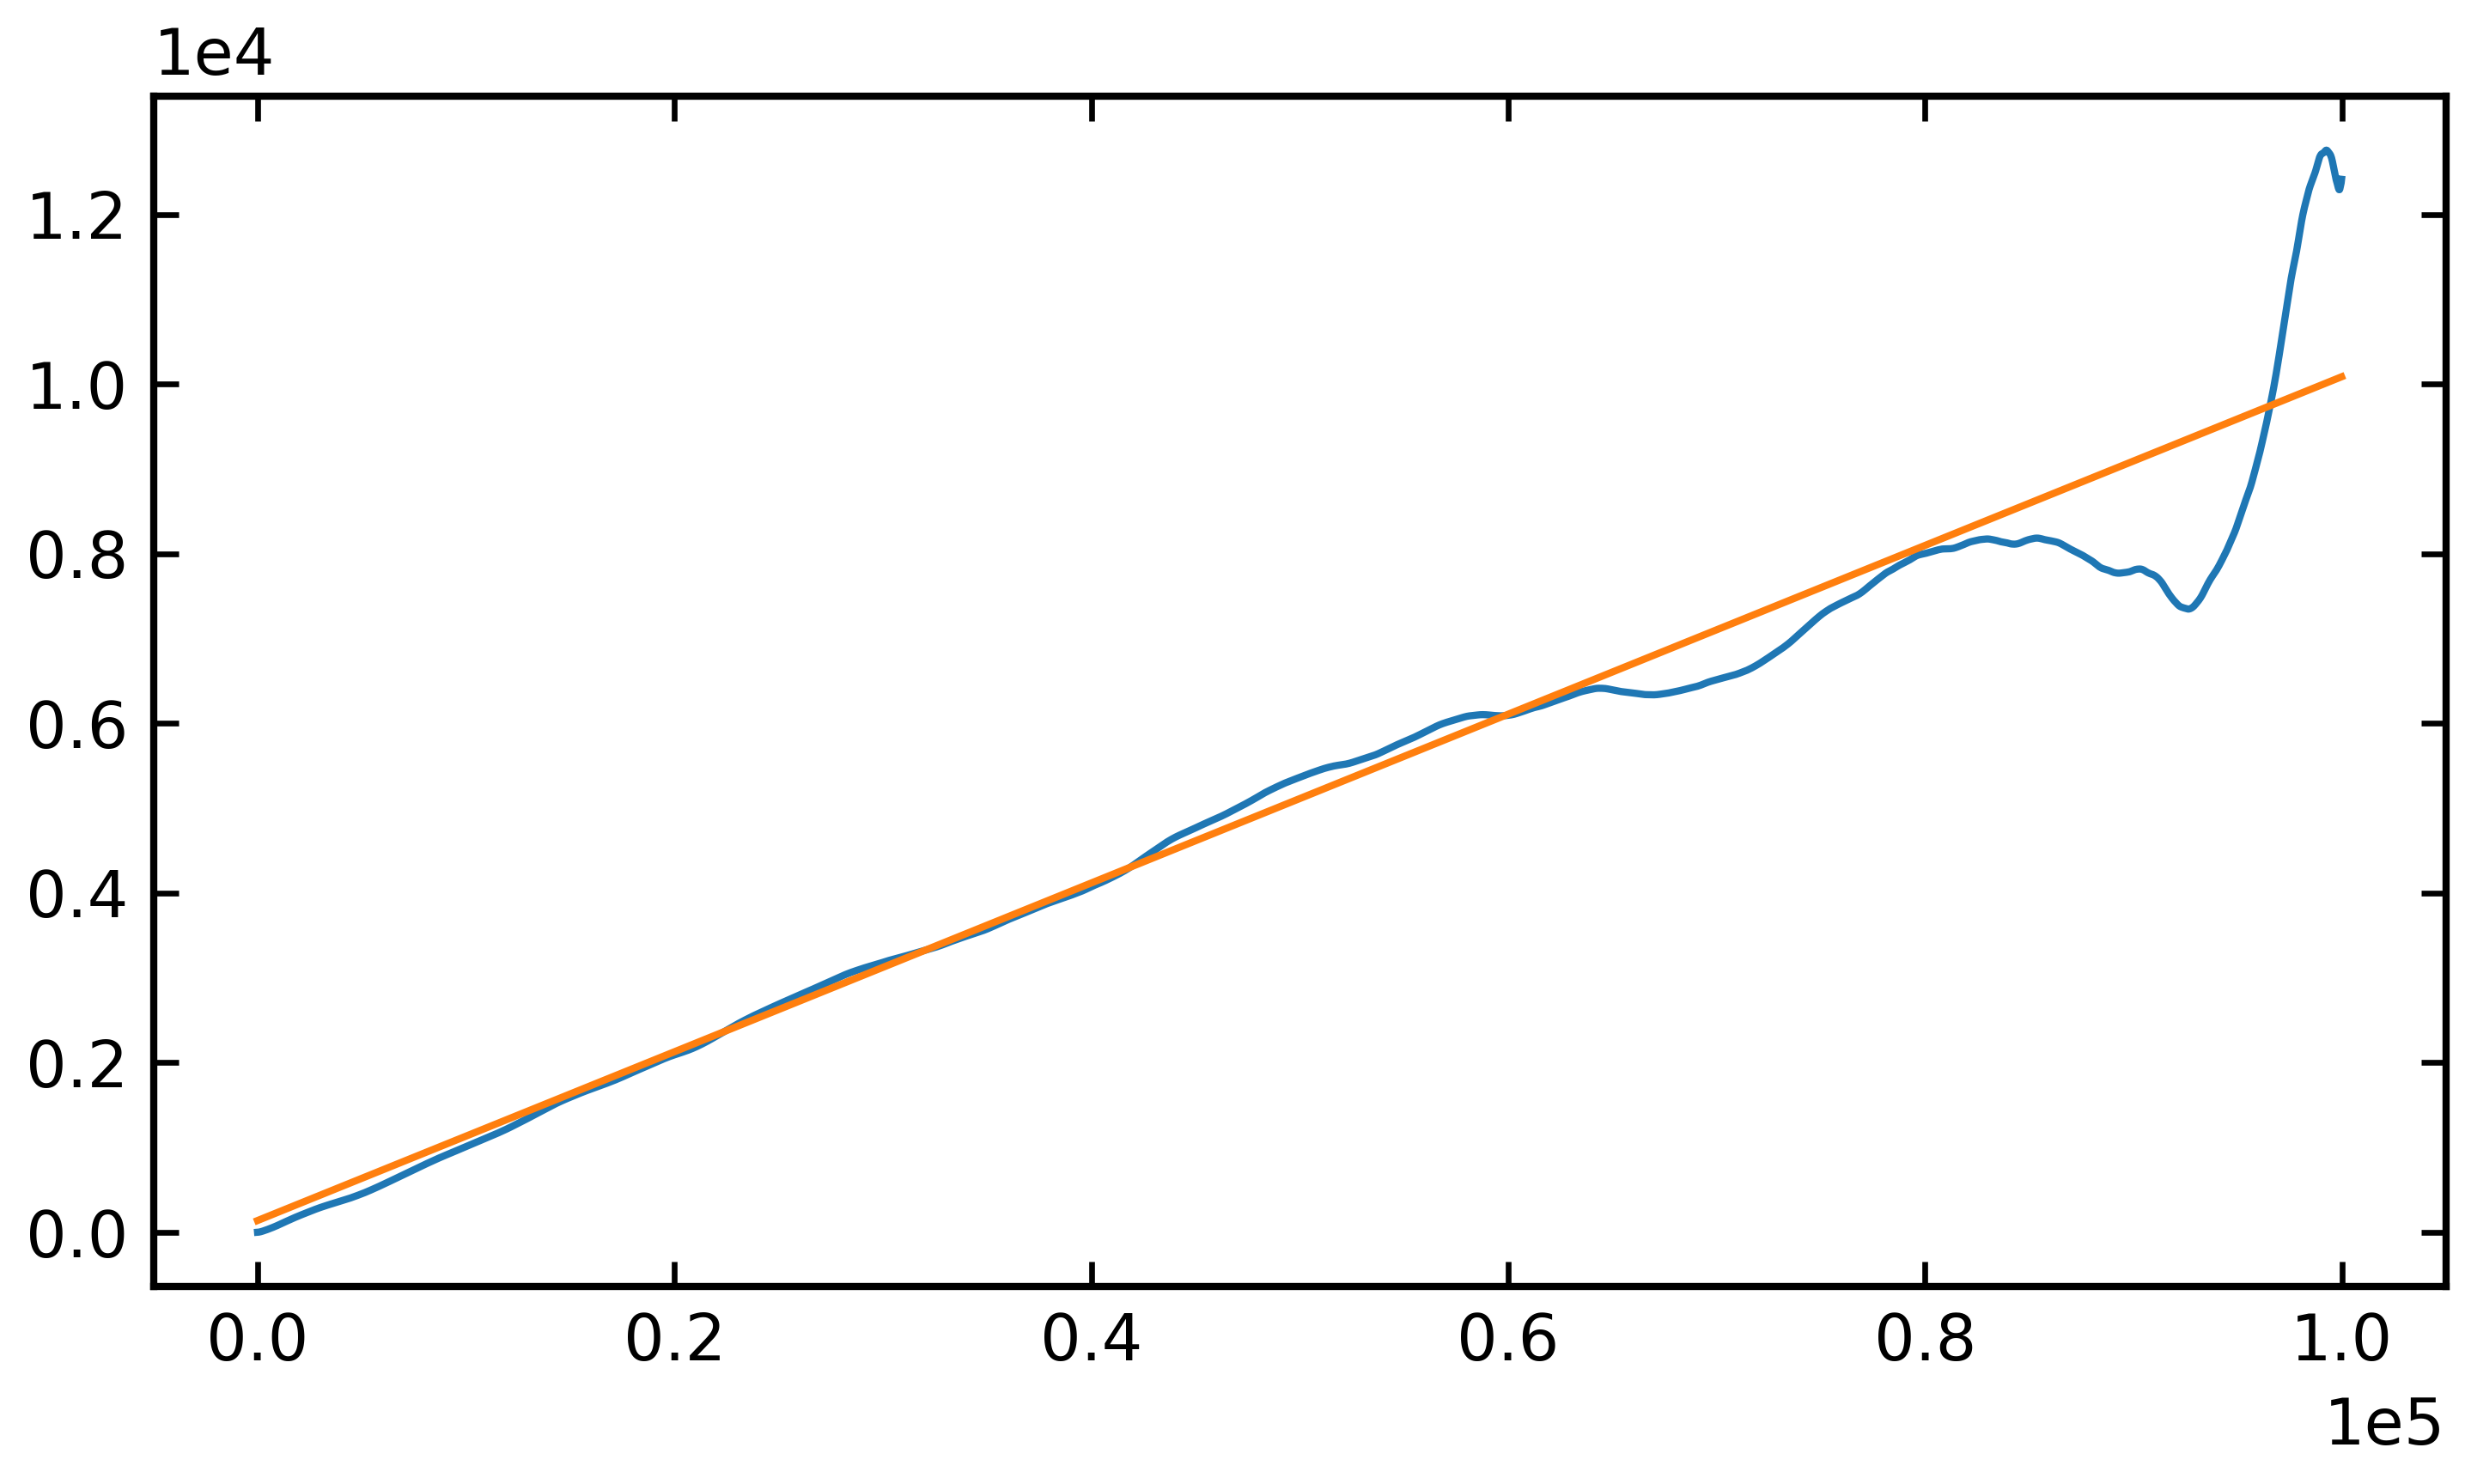

In [4]:
msd = cached(ostw_an + 'msd_dilute_single_chain.npz',
             lambda: dict(msd=com_msd(AN + 'compute_diffusion_dilute/'
                                      'sim_single-tdp43-lcd_short/sim_p-tdp43_short_dump_unwrapped.gsd')))['msd']
time = np.arange(len(msd)) * DT_MD * 2000    # dump every 2000 steps
D_out, dD_out = diffusion_coefficient(time, msd, fit=slice(750, 2000), label='dilute')

## Dense phase (equilibrium droplet, 5 pSer per chain)
All the chains whose centre of mass stays inside $R - w$ of the droplet during the whole lag window (centred dump),
at short lags (2-16 ns), since longer displacements are limited by the droplet size ($R \approx 11$ nm).

Diffusion coefficient in dense = 420 nm^2/us (6778-21084 samples per lag)


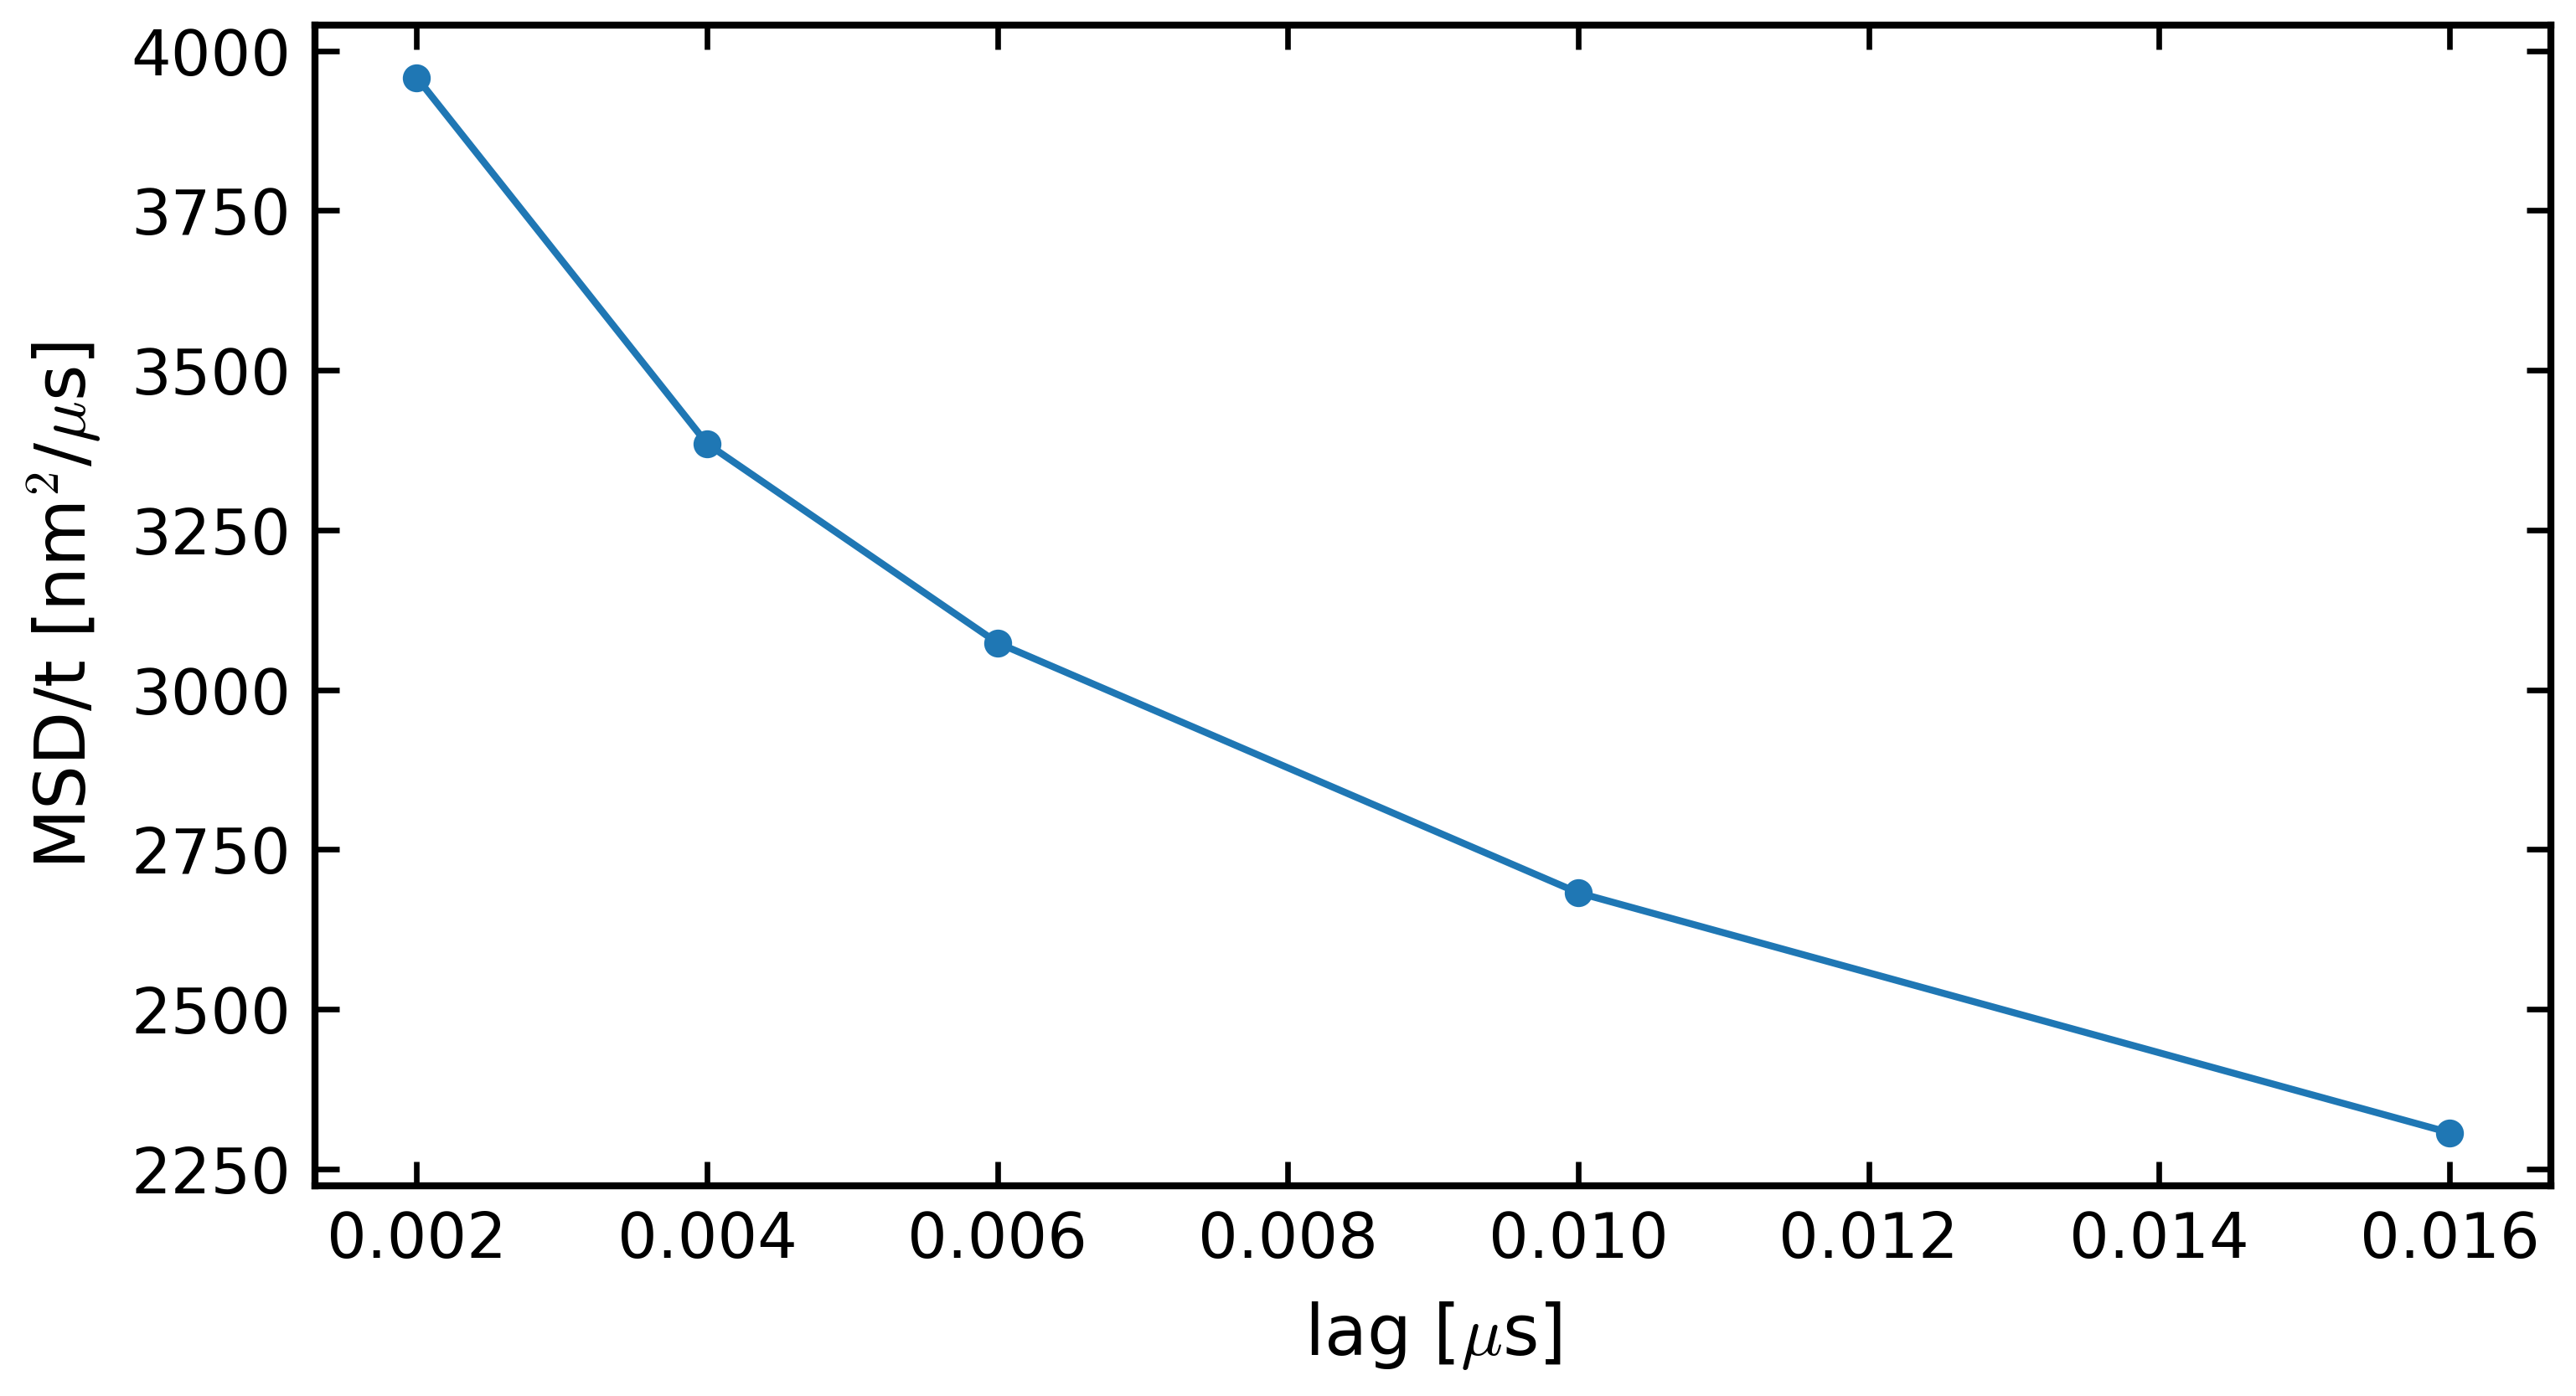

In [5]:
def dense_phase_msd(gsd_file, n_chains=200, chain_length=154, therm=25, r_in=8.5, lags=(1, 2, 3, 5, 8)):
    '''Window MSD of the chain COMs inside the droplet (|COM| < r_in during the whole window); dump every 2e5 steps.'''
    with gsd.hoomd.open(gsd_file, 'r') as traj:
        m = traj[0].particles.mass[:n_chains * chain_length].reshape(n_chains, chain_length)
        com = np.array([np.einsum('ij,ijk->ik', m, frame.particles.position[:n_chains * chain_length]
                                  .reshape(n_chains, chain_length, 3)) / m.sum(axis=1)[:, None] for frame in traj[therm:]])
    msd, nsamp = masked_msd(com, np.linalg.norm(com, axis=2) < r_in, lags)
    return dict(lag_us=np.asarray(lags) * DT_MD * 200000 * 1e-6, msd=msd, n_samples=nsamp)


dense = cached(ostw_an + 'msd_dense_eq_200-tdp43-lcd-5pser.npz', lambda: dense_phase_msd(
    path_pser + 'sim_eq_200-tdp43-lcd-5pser_fr01/sim1_eq_200-tdp43-lcd-5pser_CAL3_fr01_dump_centered.gsd'))
D_in = diffusion_through_origin(dense['lag_us'], dense['msd'])
plt.plot(dense['lag_us'], dense['msd'] / dense['lag_us'], 'o-')
plt.xlabel(r'lag [$\mu$s]')
plt.ylabel(r'MSD/t [nm$^2$/$\mu$s]')
print(f'Diffusion coefficient in dense = {D_in:.0f} nm^2/us ({dense["n_samples"].min()}-{dense["n_samples"].max()} samples per lag)')

# 2. Concentrations at equilibrium
Total, A and B density profiles of the slab and of the droplets, fitted with a tanh profile.

In [27]:
groups = {'A': lambda x: 0 <= x < THRESHOLD, 'B': lambda x: x >= THRESHOLD}
SLAB_DIR = path_struct + 'sim_eq_slab_400-tdp43-lcd_5-pp3_CAL3_fr01/'


def slab_dump(r):
    '''Centred dump of replica r of the 400-LCD slab with 1715 pSer and 5 PP3 (CAL3).'''
    return SLAB_DIR + f'sim{r}_eq_slab_400-tdp43-lcd-1715pser_5-com-pp3_CAL3_fr01_dump_centered.gsd'


def slab_log(r):
    return SLAB_DIR + f'sim{r}_eq_slab_400-tdp43-lcd-1715pser_5-com-pp3_CAL3_fr01_log.gsd'

## Slab
400 TDP-43 LCD chains with 1715 pSer and 5 PP3 (CAL3), replicas `SLAB_REPLICAS`. There are no kinases in the slab, so
the pSer of every chain do not change: a chain is A (fewer than `THRESHOLD` pSer) or B for the whole run.

1. density profiles along $z$ of every replica (slab centred at $z = 0$): all TDP-43 beads, and split by the number of
   pSer of the chain; averaged over the replicas weighted by their frames
2. total density: tanh fit of the $z \ge 0$ half
3. A and B densities: sums of the profiles of the A and B chains, symmetrised ($z$ and $-z$ averaged), tanh fits
4. dilute A concentration of the slab `c_out_A_sl_mean`: mean A density over the outer half of $z \ge 0$
   ($L_z/4 < z < L_z/2$, far from the interface), used for $R_{stab}$

In [30]:
SLAB_THERM = 200     # frames skipped at the start of every replica
SLAB_NAME = 'slab_profiles_400-tdp43-lcd-1715pser_5-pp3_CAL3'
N_SLAB_CHAINS = 400


def compute_slab_profiles(dump):
    '''Density profiles along z of one replica (200 bins over the box):
    density: all TDP-43 beads; profiles[i]: beads of the chains with classes[i] pSer, counts[i] of these chains.'''
    z, total = hpa.profiles.compute_density_profile(dump, axis=2, nbins=200, group=np.arange(N_SLAB_CHAINS * CHAIN_LENGTH),
                                                    therm=SLAB_THERM)
    _, by_npser, chains = hpa.profiles.compute_density_profile_by_npSer(dump, n_chains=N_SLAB_CHAINS,
                                                                       beads_per_chain=CHAIN_LENGTH, nbins=200,
                                                                       therm=SLAB_THERM)
    return dict(bins=z, density=total, **profiles_to_arrays(by_npser, chains), frames_used=dump_frames(dump) - SLAB_THERM)


# 1. profiles of every replica, saved in ostw_an/{SLAB_NAME}_sim{r}.npz (recomputed if its dump has grown)
slab_replicas = {}
for r in SLAB_REPLICAS:
    p = replica_cached(f'{ostw_an}{SLAB_NAME}_sim{r}.npz', slab_dump(r), lambda: compute_slab_profiles(slab_dump(r)))
    if p is not None:
        slab_replicas[r] = p

# average over the replicas weighted by their frames (same pSer pattern in all replicas: same classes and counts)
if slab_replicas:
    frames = {r: float(p['frames_used']) for r, p in slab_replicas.items()}
    slab = dict(slab_replicas[min(slab_replicas)])
    for k in ('density', 'profiles'):
        slab[k] = sum(frames[r] * p[k] for r, p in slab_replicas.items()) / sum(frames.values())
    print('slab profiles: ' + ', '.join(f'sim{r} ({int(n)} frames)' for r, n in frames.items()))
else:
    print('slab profiles: WARNING no replica available, single-run profiles (made before the replicas) used')
    with np.load(ostw_an + SLAB_NAME + '.npz') as f:
        slab = {k: f[k] for k in f.files}

# 2. total density: tanh fit of the z >= 0 half (from the slab centre to the box edge)
half = len(slab['bins']) // 2
x_sl = slab['bins'][half:]
density_sl = slab['density']
fit_sl = fit_tanh_profile(x_sl, density_sl[half:])
print_fit('Slab condensate', fit_sl)

Computing density profiles: 100%|██████████████████████████████████| 2500/2500 [00:03<00:00, 719.28it/s]

slab profiles: sim1 (4800 frames), sim2 (2300 frames)
Slab condensate: 
c_in = 3.0086+-0.0018 res/nm^3, 
c_out = 0.0043+-0.0008 res/nm^3, 
w = 2.833+-0.011 nm, 
R = 16.291+-0.006 nm


In [31]:
# 3. A and B densities: sums of the profiles of the chains with < THRESHOLD pSer (A) and >= THRESHOLD pSer (B)
is_A = slab['classes'] < THRESHOLD
rho_sl = {'A': slab['profiles'][is_A].sum(axis=0), 'B': slab['profiles'][~is_A].sum(axis=0)}

# symmetrise: average of z >= 0 and of the mirrored z < 0 half, ordered from the slab centre outwards (as x_sl)
profile_sl = {k: (rho[half:] + rho[:half][::-1]) / 2 for k, rho in rho_sl.items()}

# tanh fits; initial guess c_in ~ 3, c_out ~ 0.01, w ~ 5 nm, interface at z ~ 8 nm
fit_sl_AB = {k: fit_tanh_profile(x_sl, profile_sl[k], p0=[1.5, -1.49, 0.21, 8]) for k in 'AB'}
for k in 'AB':
    print_fit('Slab condensate', fit_sl_AB[k], tag=f'_{k}')

# 4. dilute A concentration of the slab: mean A density over the outer half of z >= 0 (Lz/4 < z < Lz/2)
c_out_A_sl_mean = np.mean(profile_sl['A'][len(x_sl) // 2:])

Slab condensate: 
c_in_A = 2.5861+-0.0010 res/nm^3, 
c_out_A = 0.0017+-0.0005 res/nm^3, 
w_A = 2.901+-0.007 nm, 
R_A = 16.063+-0.004 nm
Slab condensate: 
c_in_B = 0.4279+-0.0020 res/nm^3, 
c_out_B = 0.0030+-0.0010 res/nm^3, 
w_B = 2.333+-0.084 nm, 
R_B = 17.452+-0.048 nm


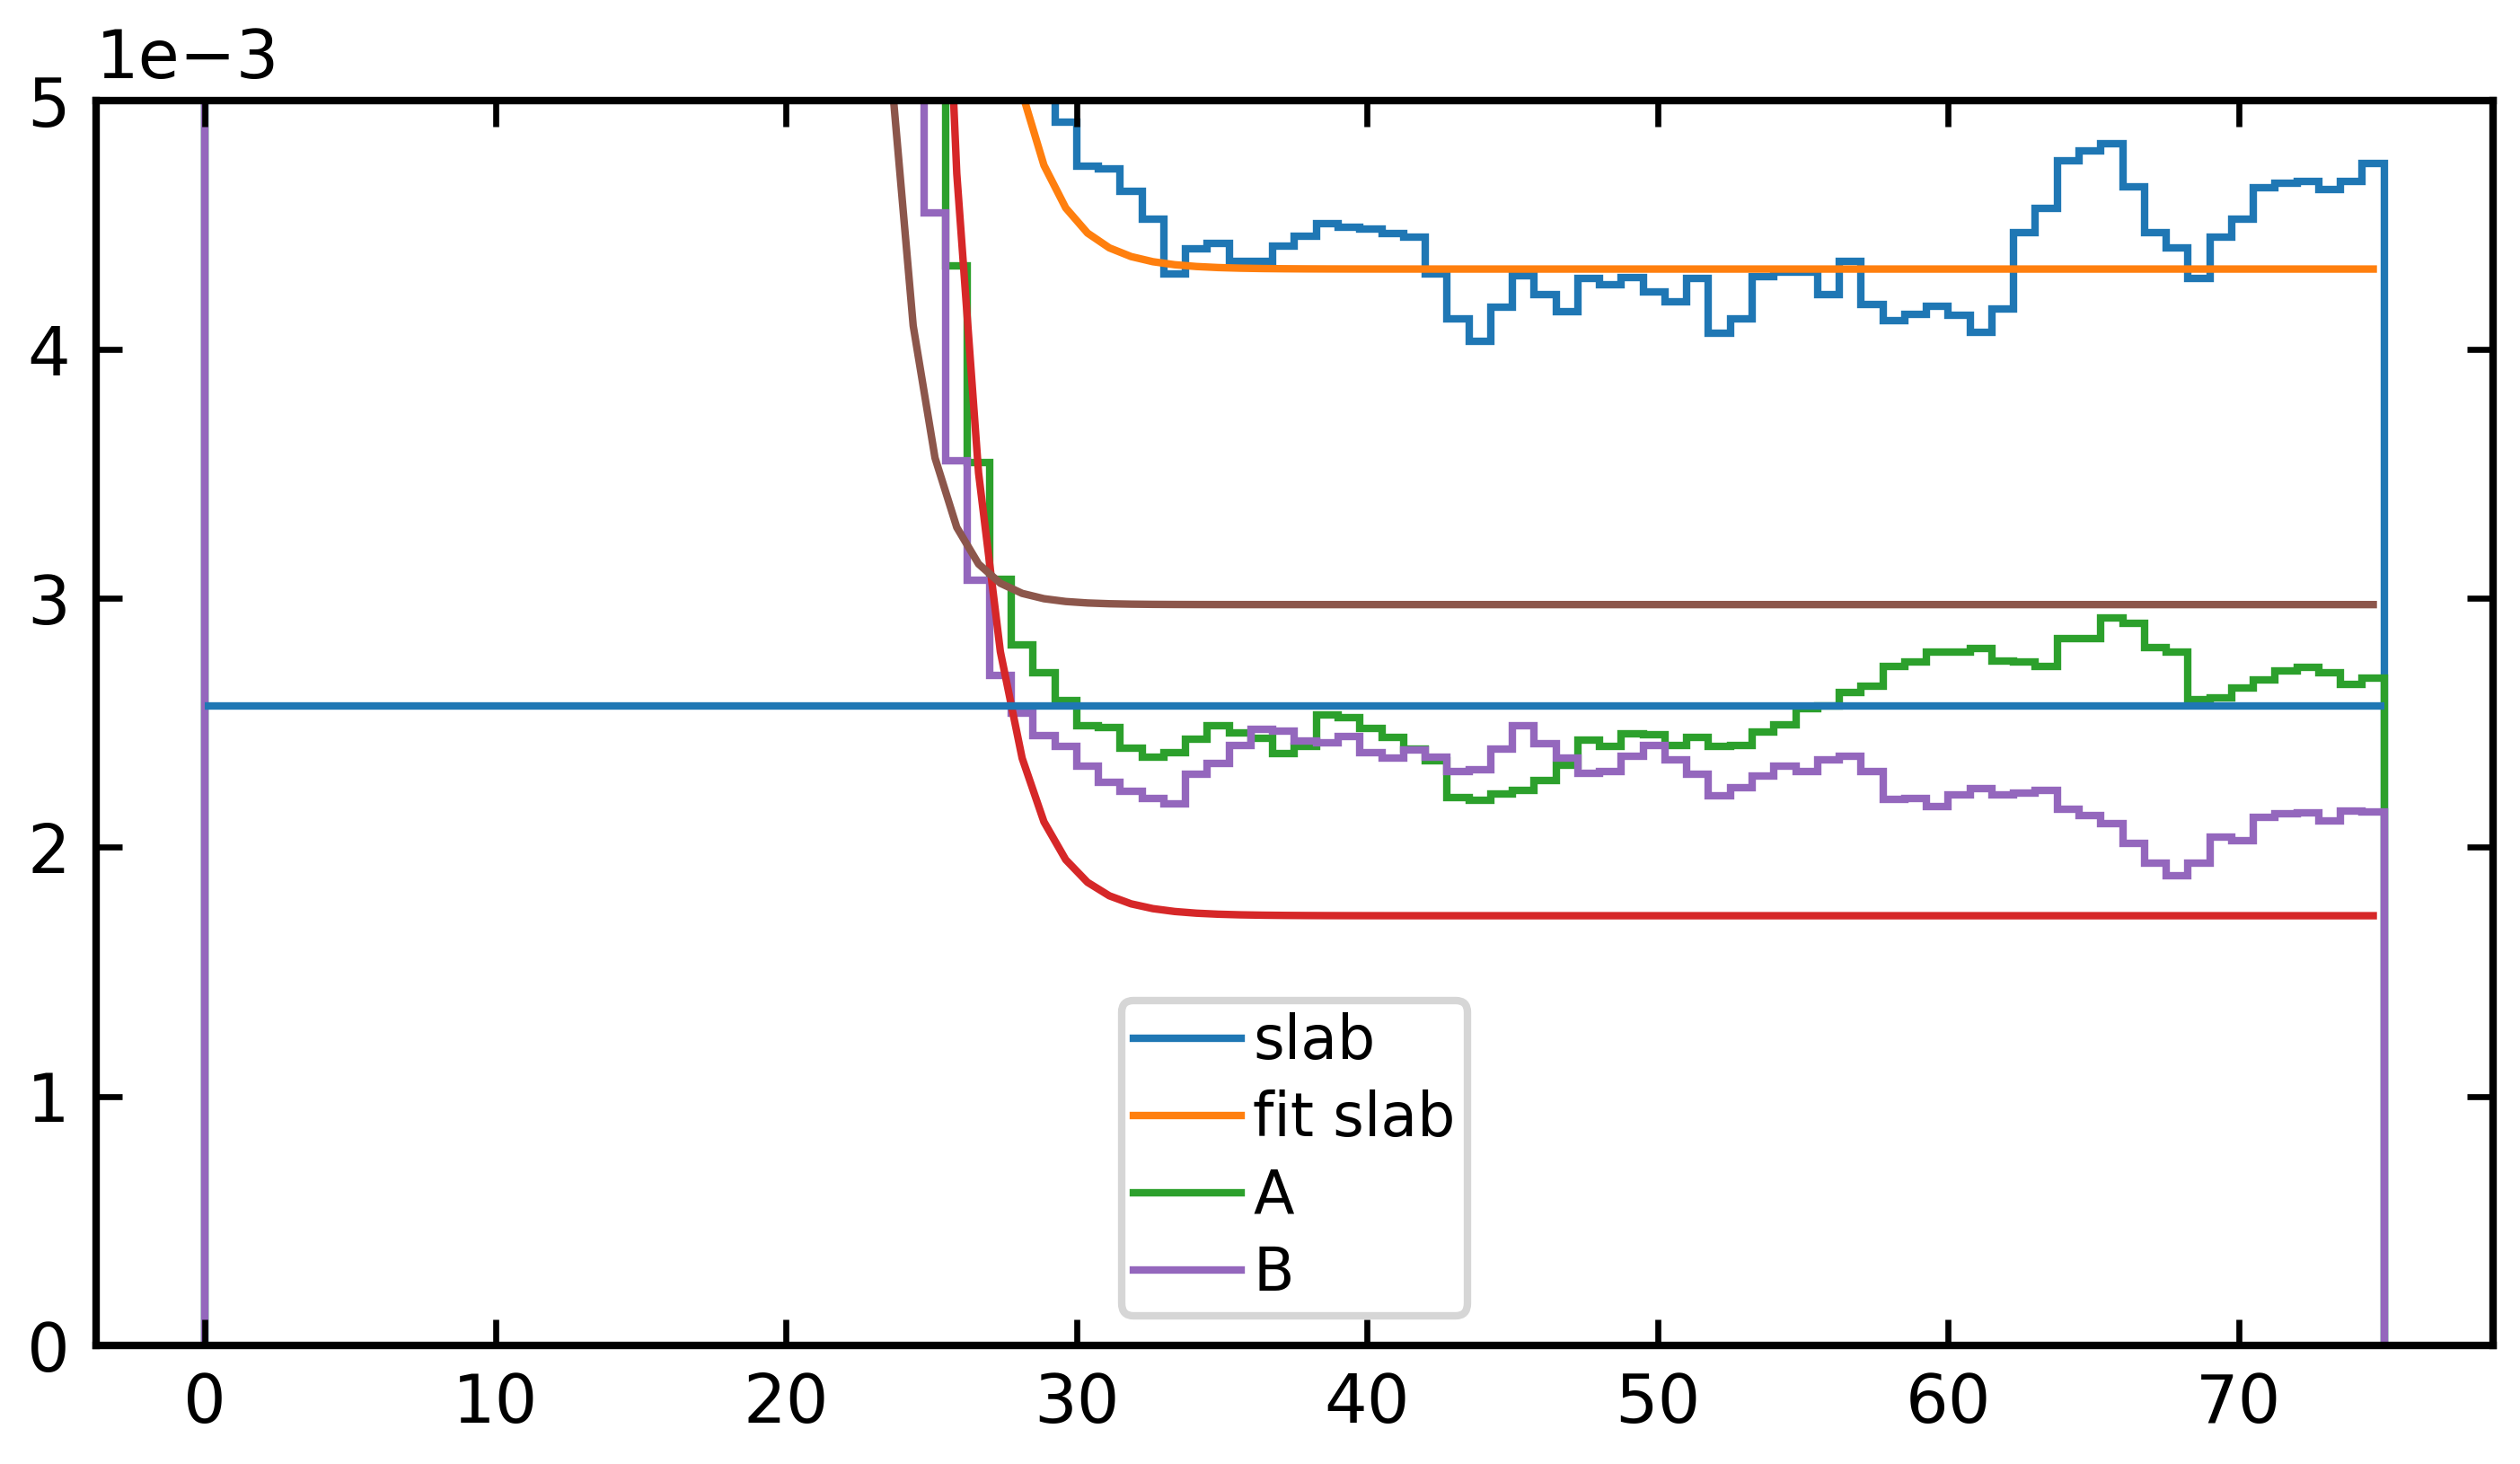

In [32]:
plt.stairs(density_sl[half:], stairs_edges(x_sl), label='slab')
plt.plot(x_sl, tanh_general(x_sl, *fit_sl['popt']), label='fit slab')
for k in 'AB':
    plt.stairs(profile_sl[k], stairs_edges(x_sl), label=k)
    plt.plot(x_sl, tanh_general(x_sl, *fit_sl_AB[k]['popt']))
plt.hlines(c_out_A_sl_mean, 0, 75)
plt.ylim(0, 0.005)
plt.legend()

## Droplets
The A/B class of every chain follows its instantaneous number of pSer. Profiles saved per replica.

$c_{out,A}(R^+)$: mean A density for $r > R + 4w$ ($R$, $w$ from the tanh fit of the total profile). The interface is wide
(the tanh tail is still above the dilute density at $R + 3w$), and beyond $R + 4w$ the A profile is flat, so this is the
dilute A density just outside the droplet. The previous definition, the minimum of the A profile (slightly biased low
by the noise), is kept in the file for comparison.

sim1 droplet condensate: 
c_in = 3.1318+-0.0040 res/nm^3, 
c_out = 0.0074+-0.0017 res/nm^3, 
w = 2.885+-0.019 nm, 
R = 11.567+-0.011 nm


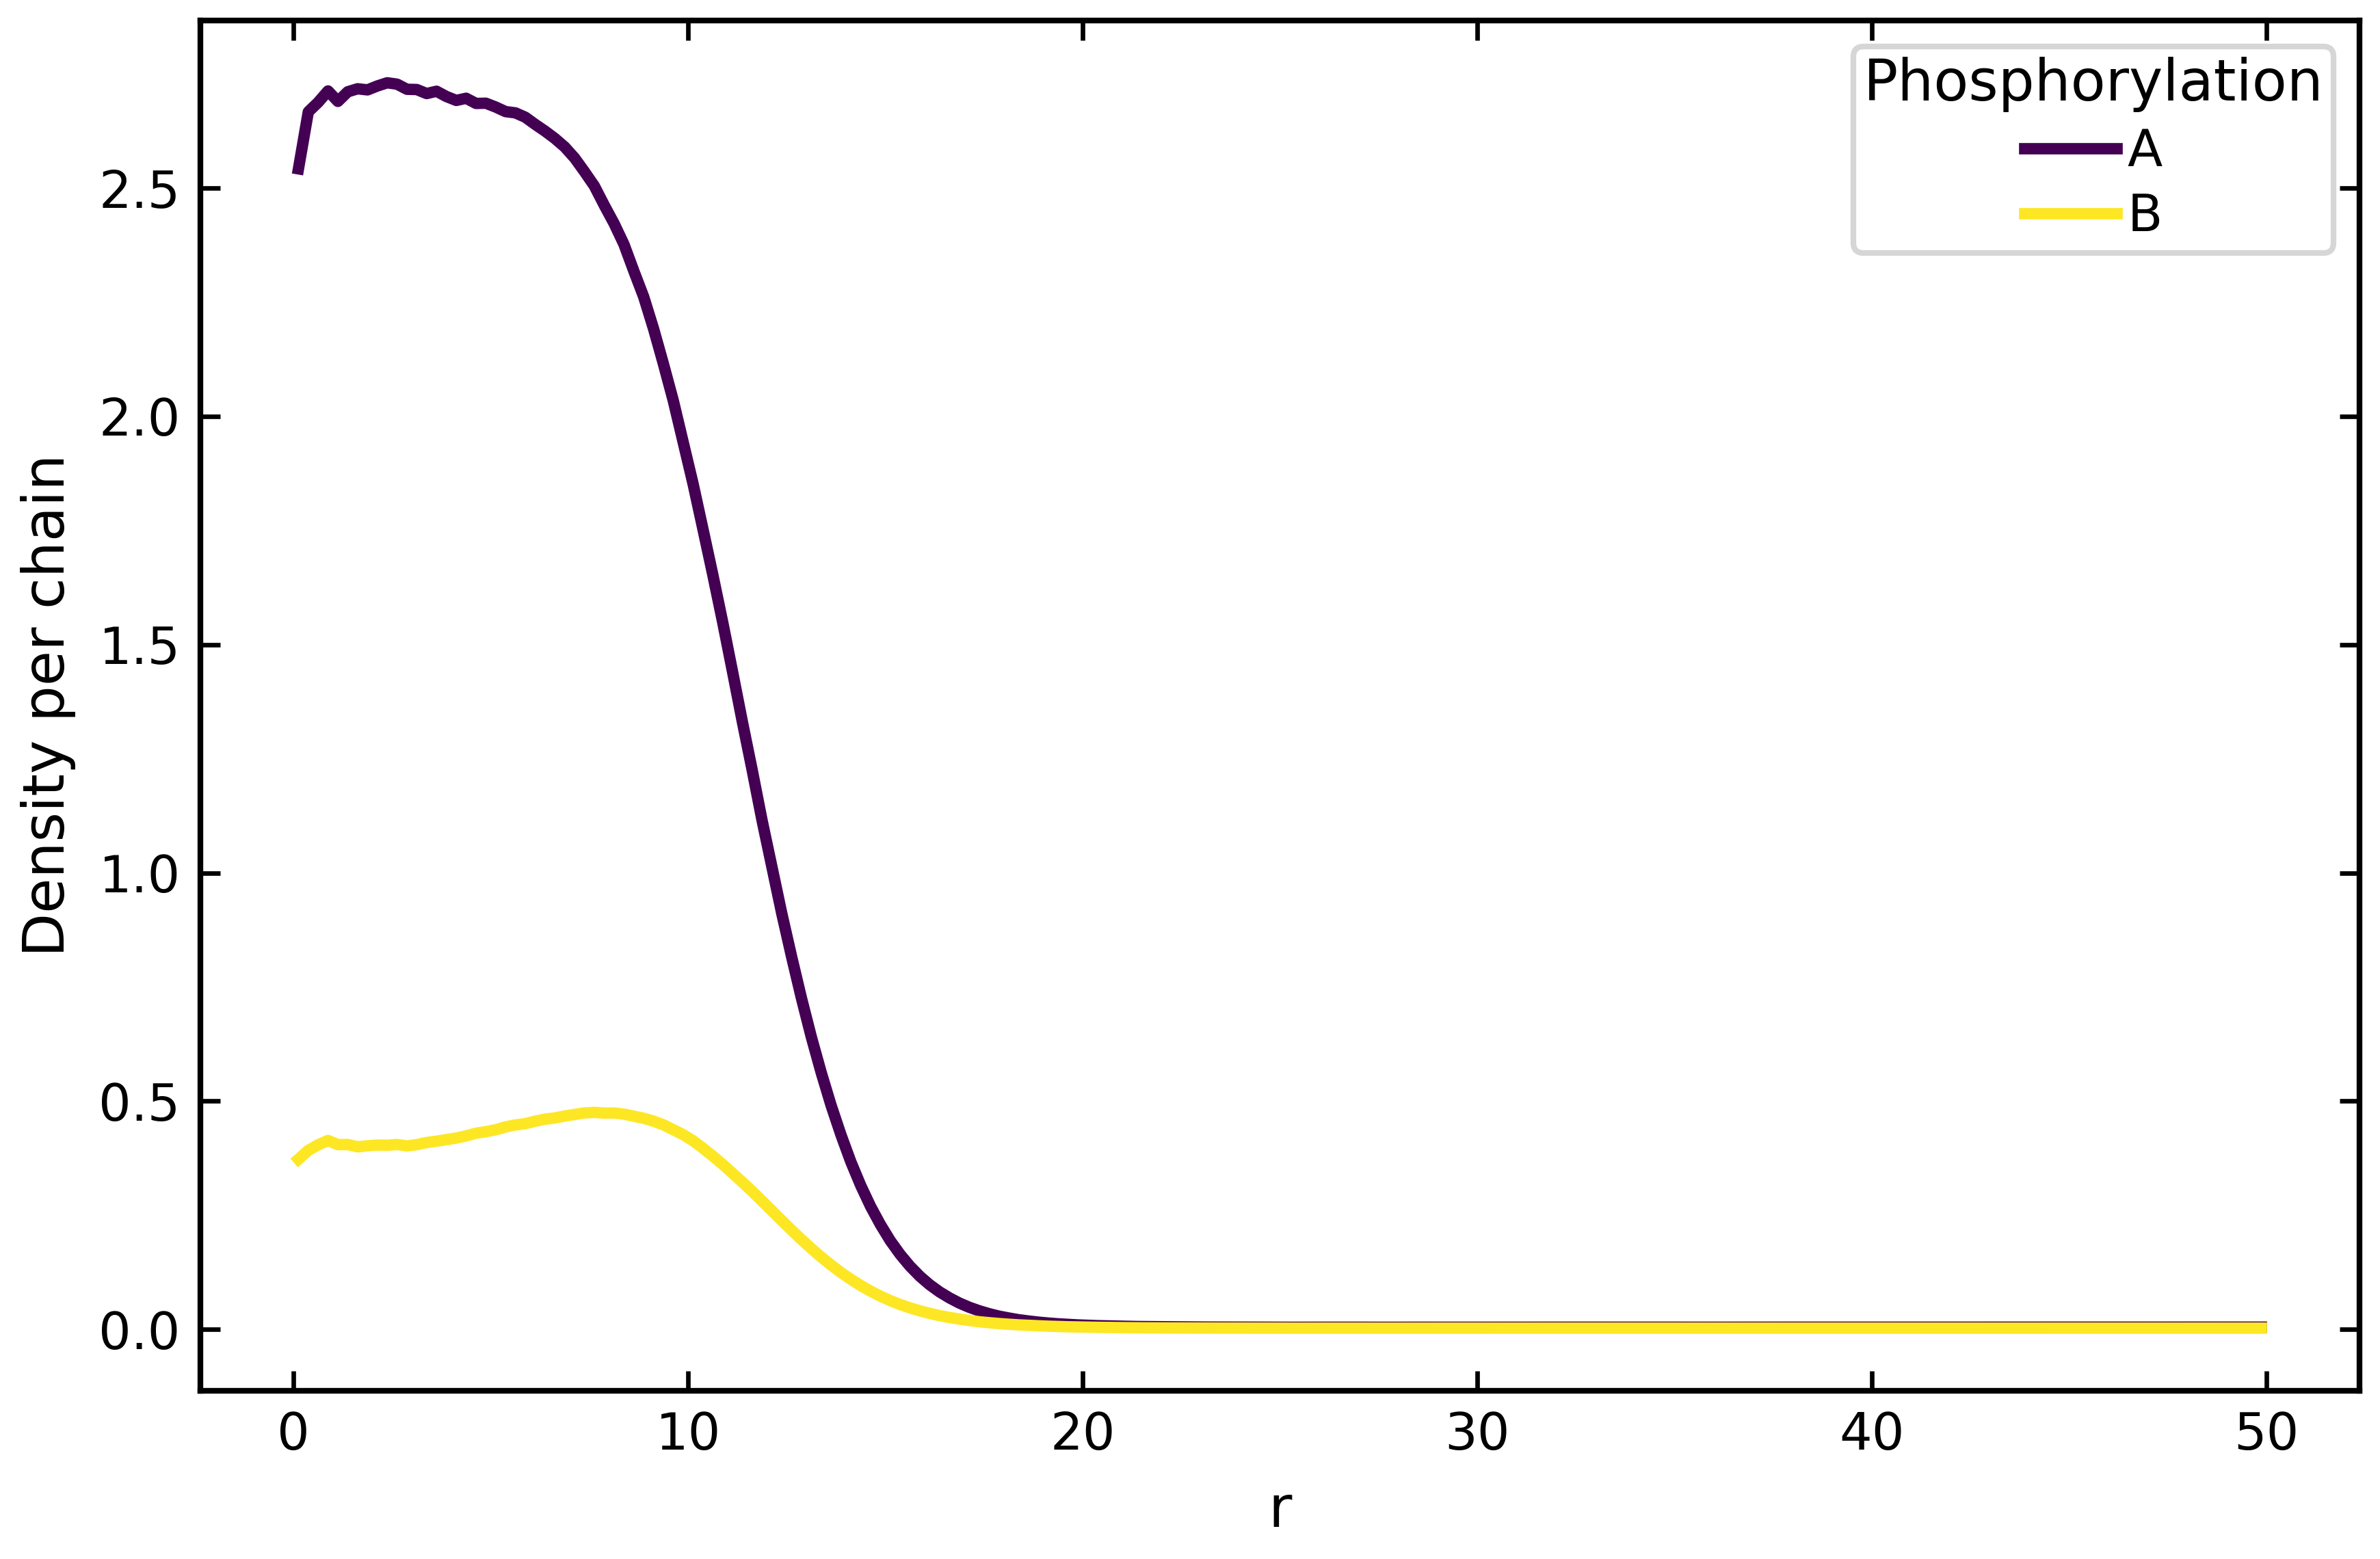

sim1 droplet condensate: 
c_in_A = 2.7121+-0.0029 res/nm^3, 
c_out_A = 0.0034+-0.0012 res/nm^3, 
w_A = 3.009+-0.016 nm, 
R_A = 11.315+-0.009 nm
sim1 droplet condensate: 
c_in_B = 0.4354+-0.0026 res/nm^3, 
c_out_B = 0.0039+-0.0013 res/nm^3, 
w_B = 2.224+-0.087 nm, 
R_B = 12.737+-0.050 nm
sim1: c_out_A(R+) = 0.00468 (r > R + 4w), 0.00451 (minimum) res/nm^3
sim2 droplet condensate: 
c_in = 3.1477+-0.0020 res/nm^3, 
c_out = 0.0067+-0.0009 res/nm^3, 
w = 2.915+-0.010 nm, 
R = 11.652+-0.006 nm


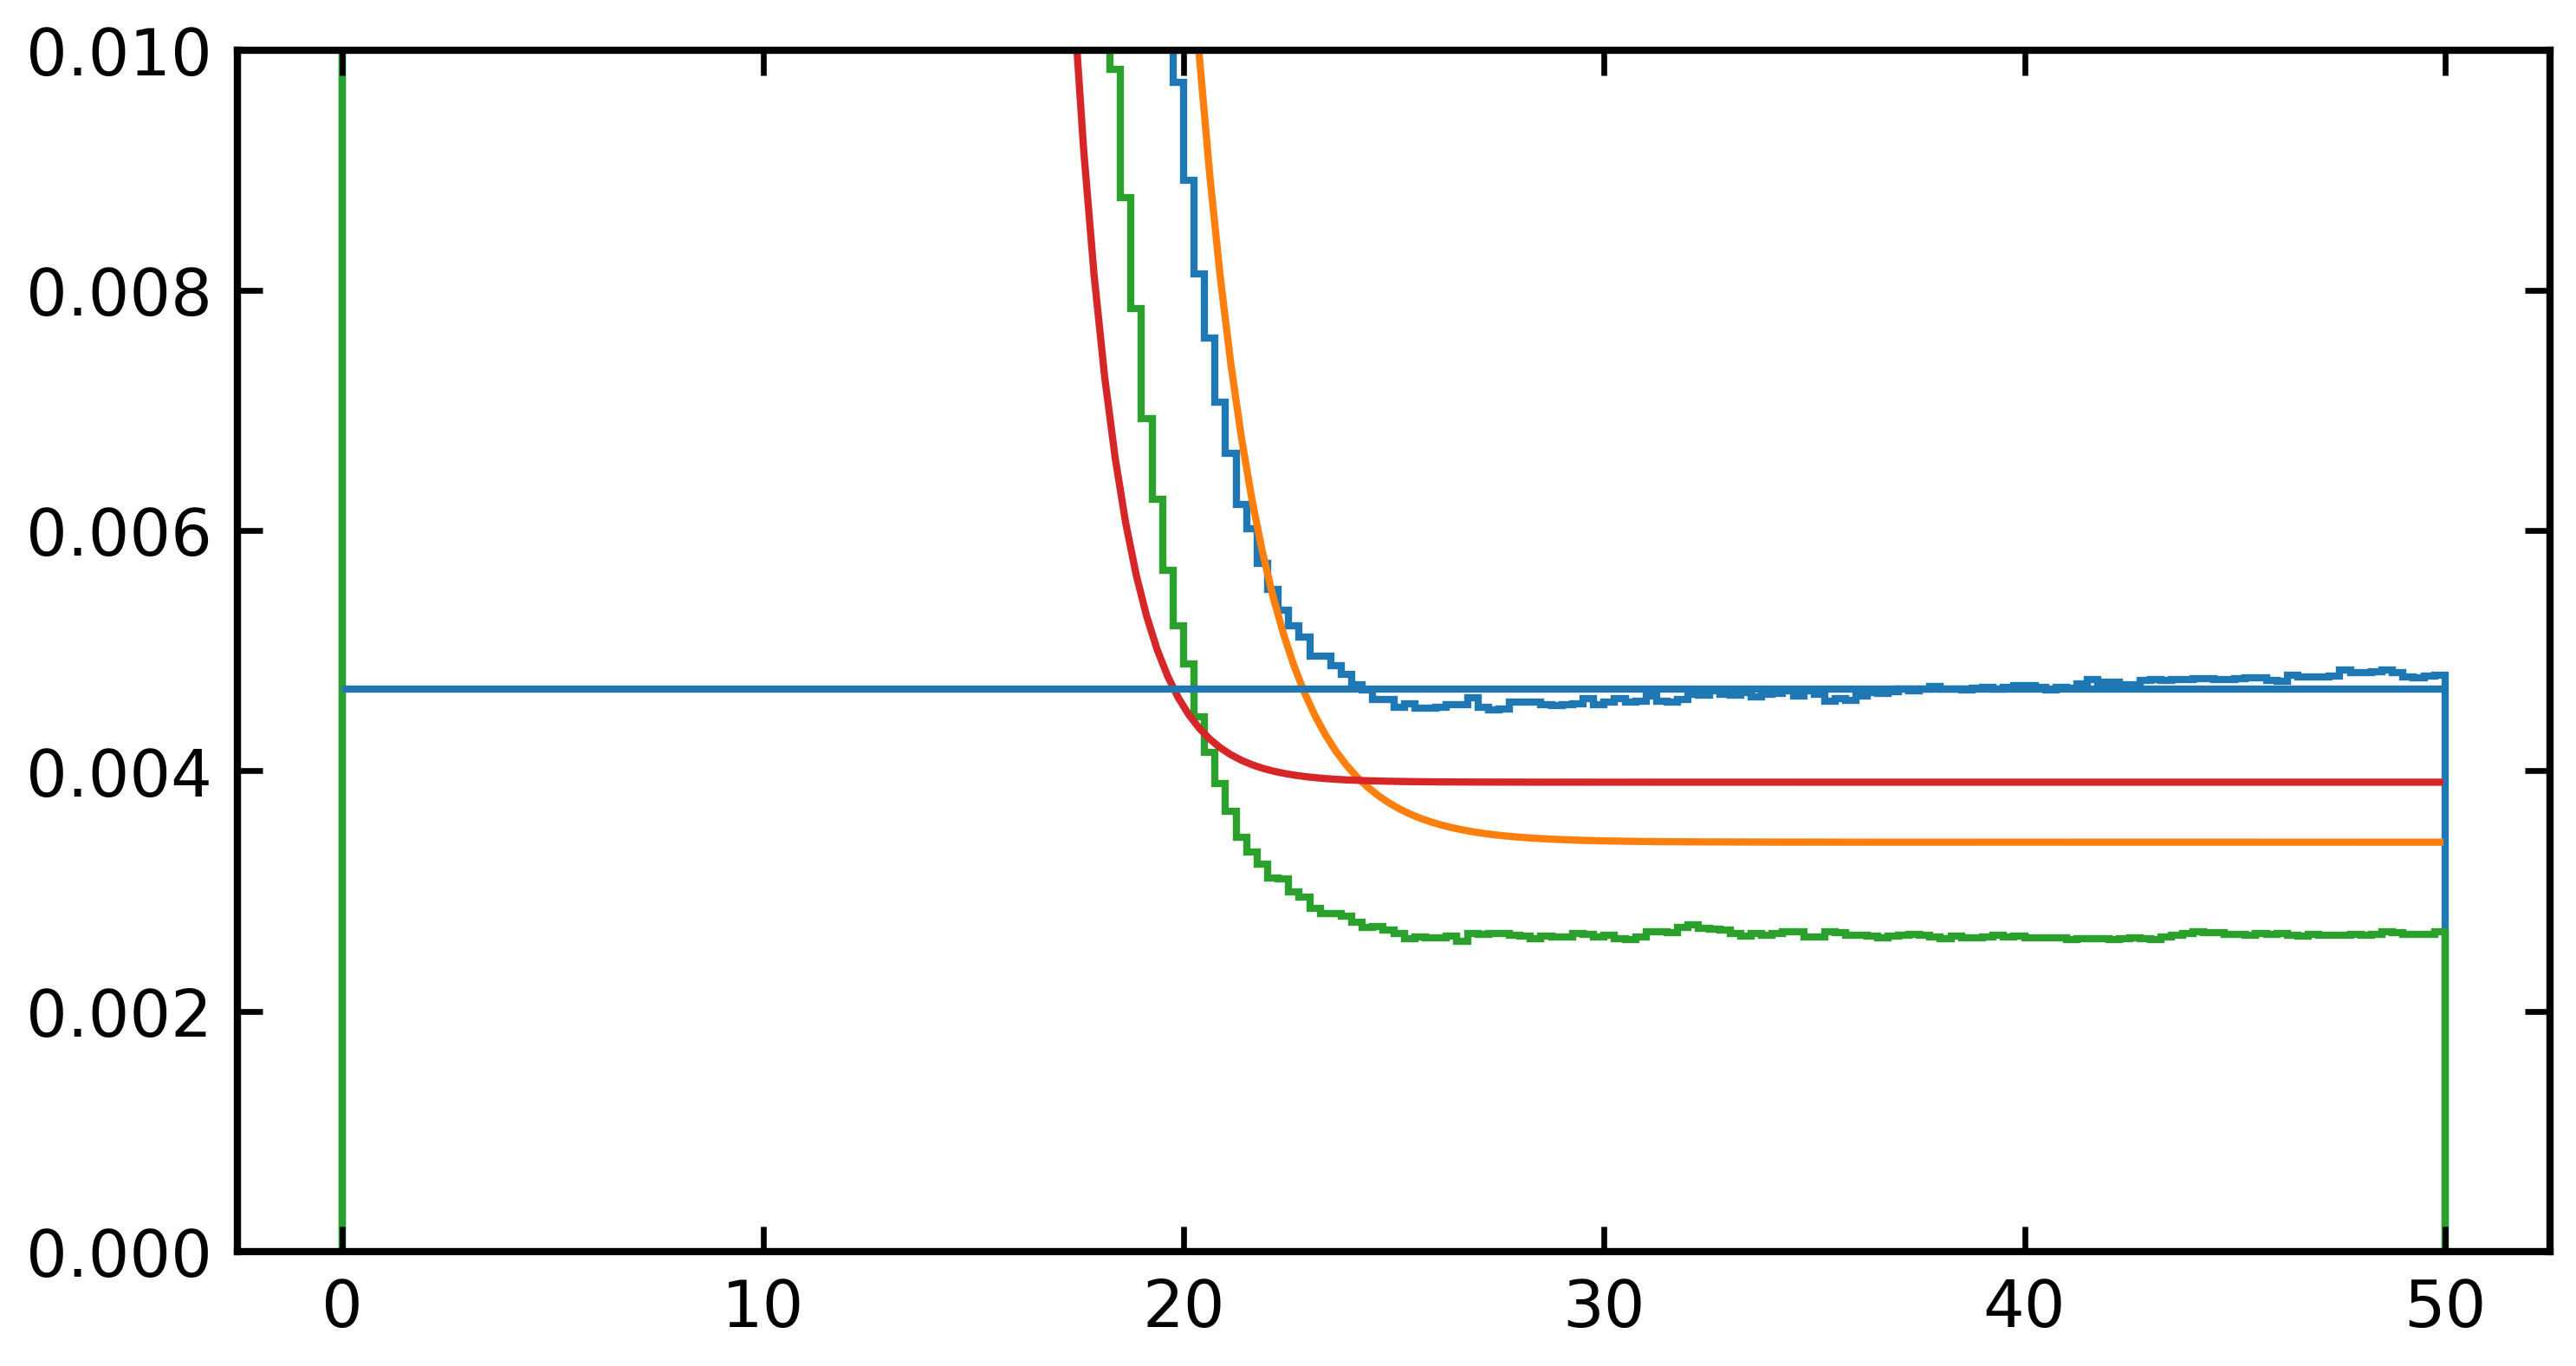

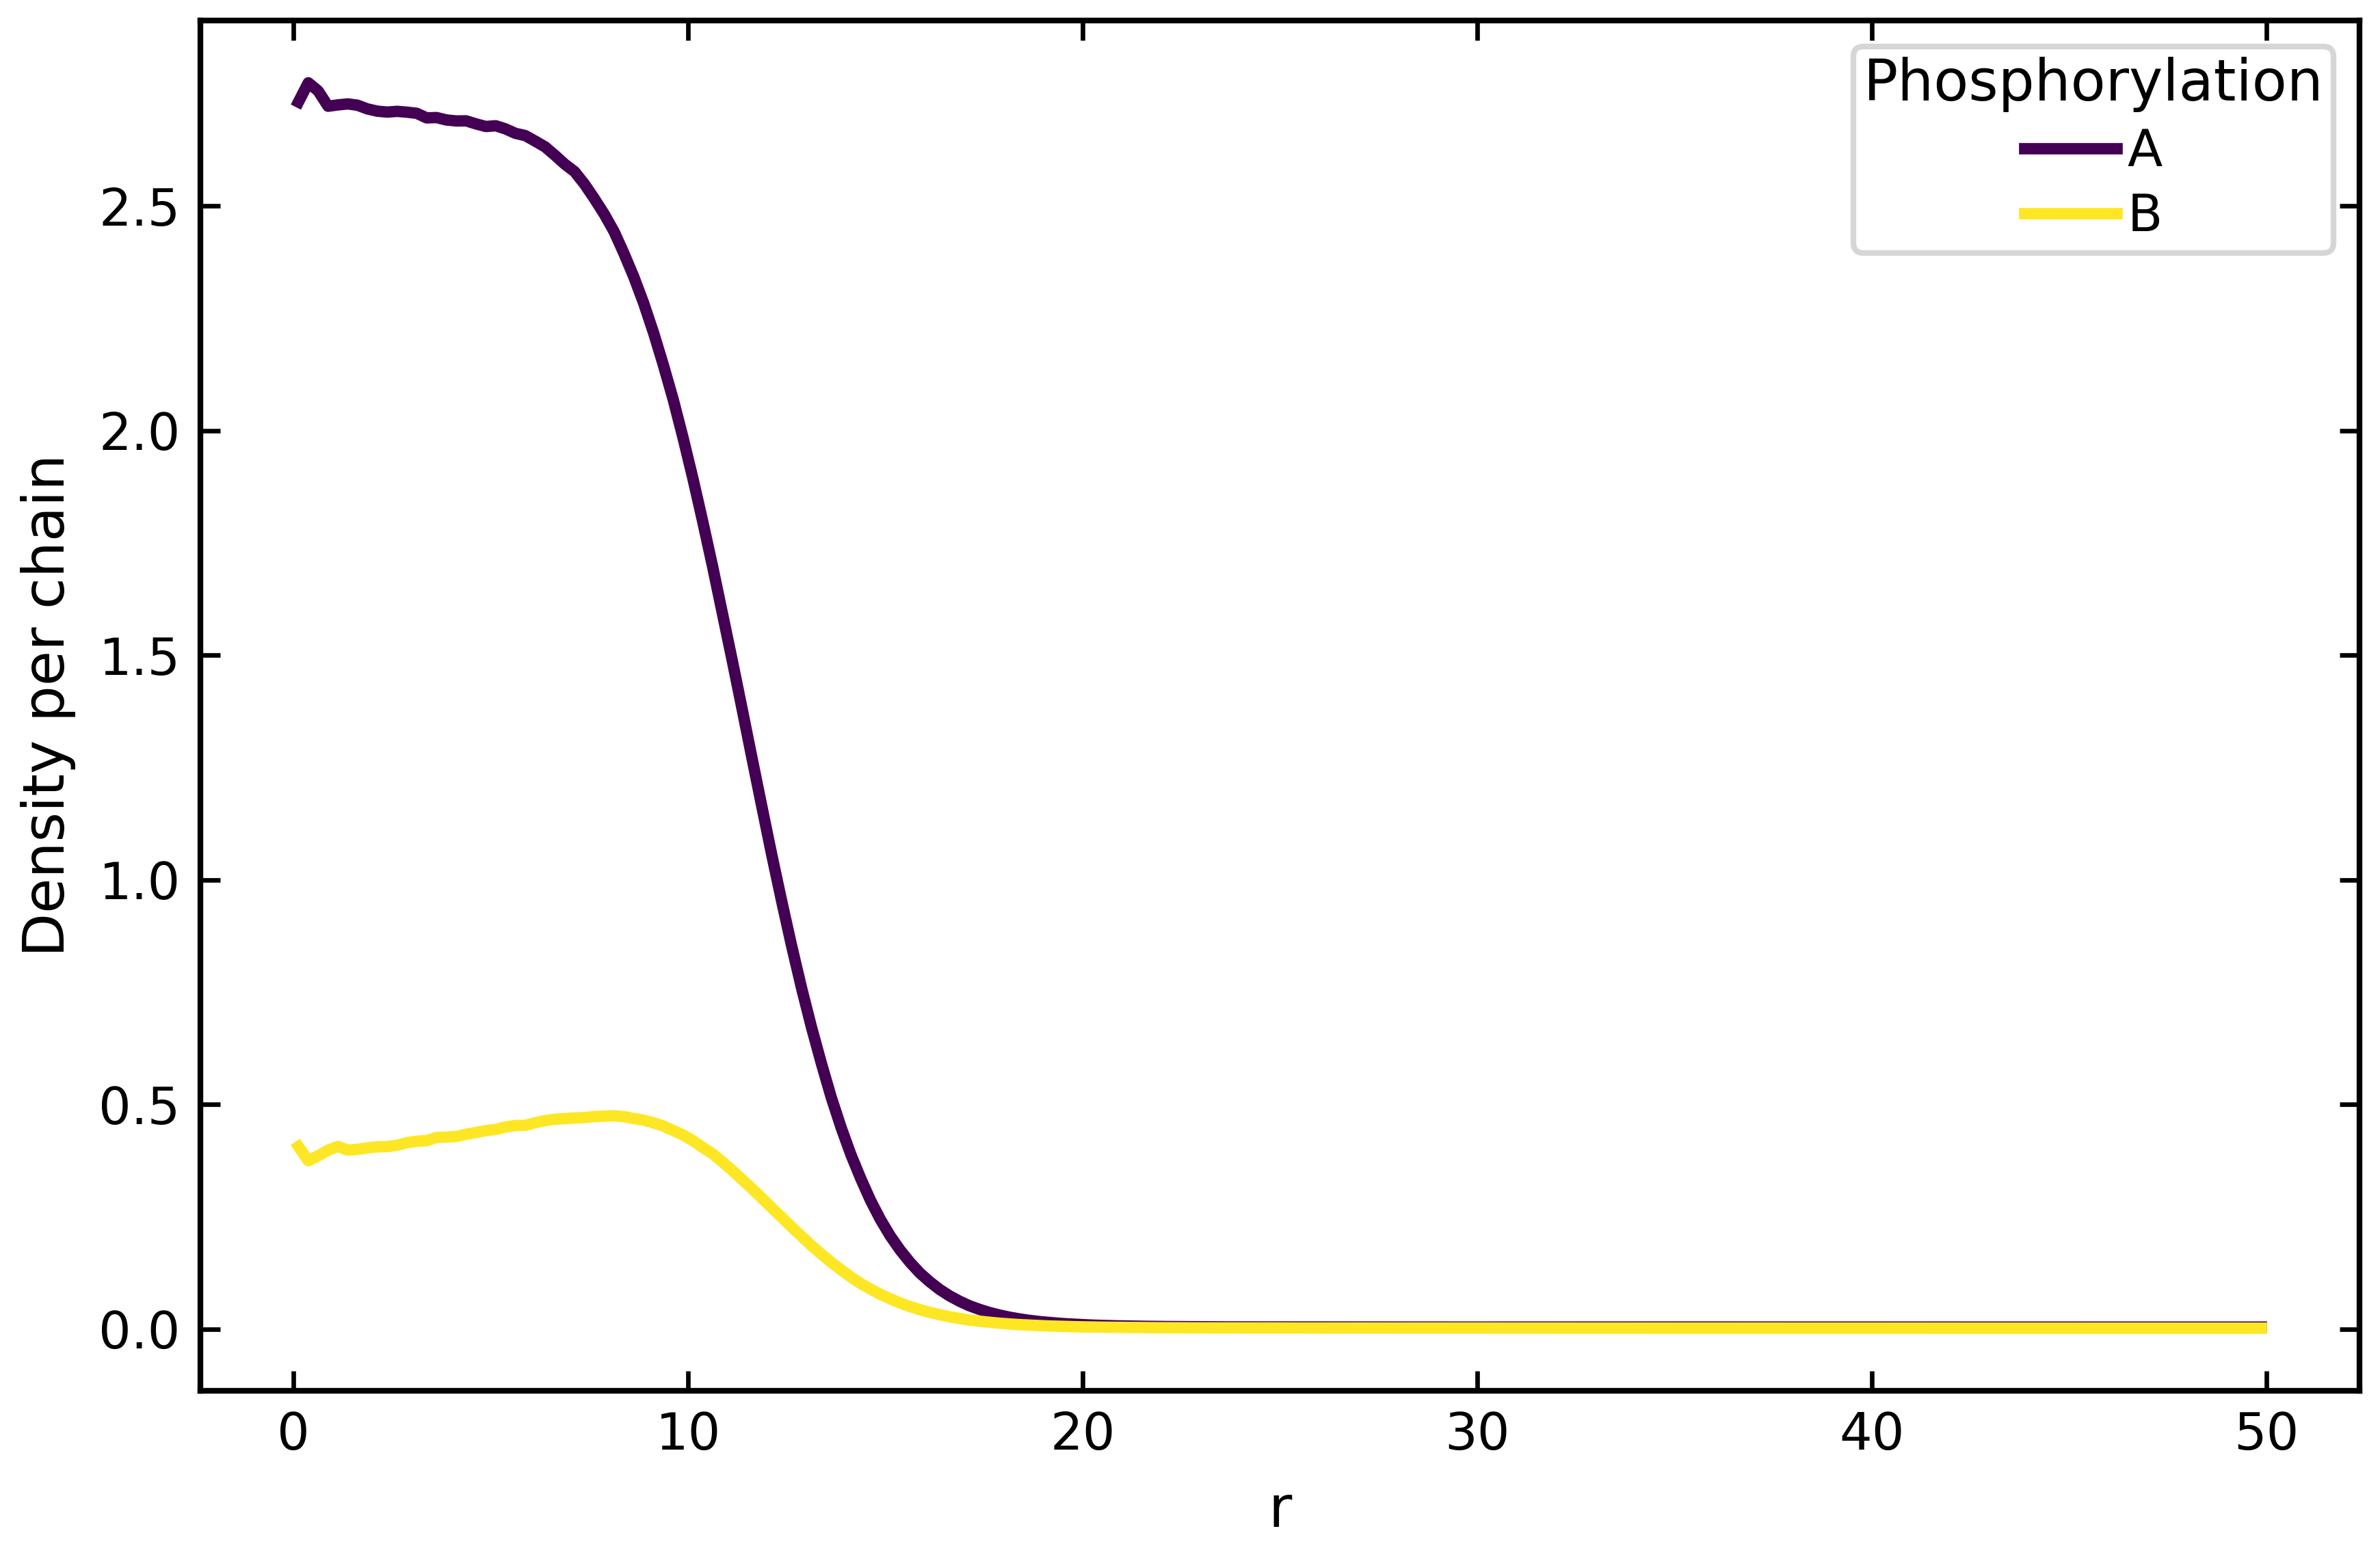

sim2 droplet condensate: 
c_in_A = 2.7244+-0.0014 res/nm^3, 
c_out_A = 0.0030+-0.0006 res/nm^3, 
w_A = 3.042+-0.008 nm, 
R_A = 11.396+-0.005 nm
sim2 droplet condensate: 
c_in_B = 0.4392+-0.0025 res/nm^3, 
c_out_B = 0.0036+-0.0013 res/nm^3, 
w_B = 2.248+-0.086 nm, 
R_B = 12.834+-0.049 nm
sim2: c_out_A(R+) = 0.00461 (r > R + 4w), 0.00452 (minimum) res/nm^3
sim3 droplet condensate: 
c_in = 3.1215+-0.0027 res/nm^3, 
c_out = 0.0077+-0.0012 res/nm^3, 
w = 2.958+-0.013 nm, 
R = 11.476+-0.008 nm


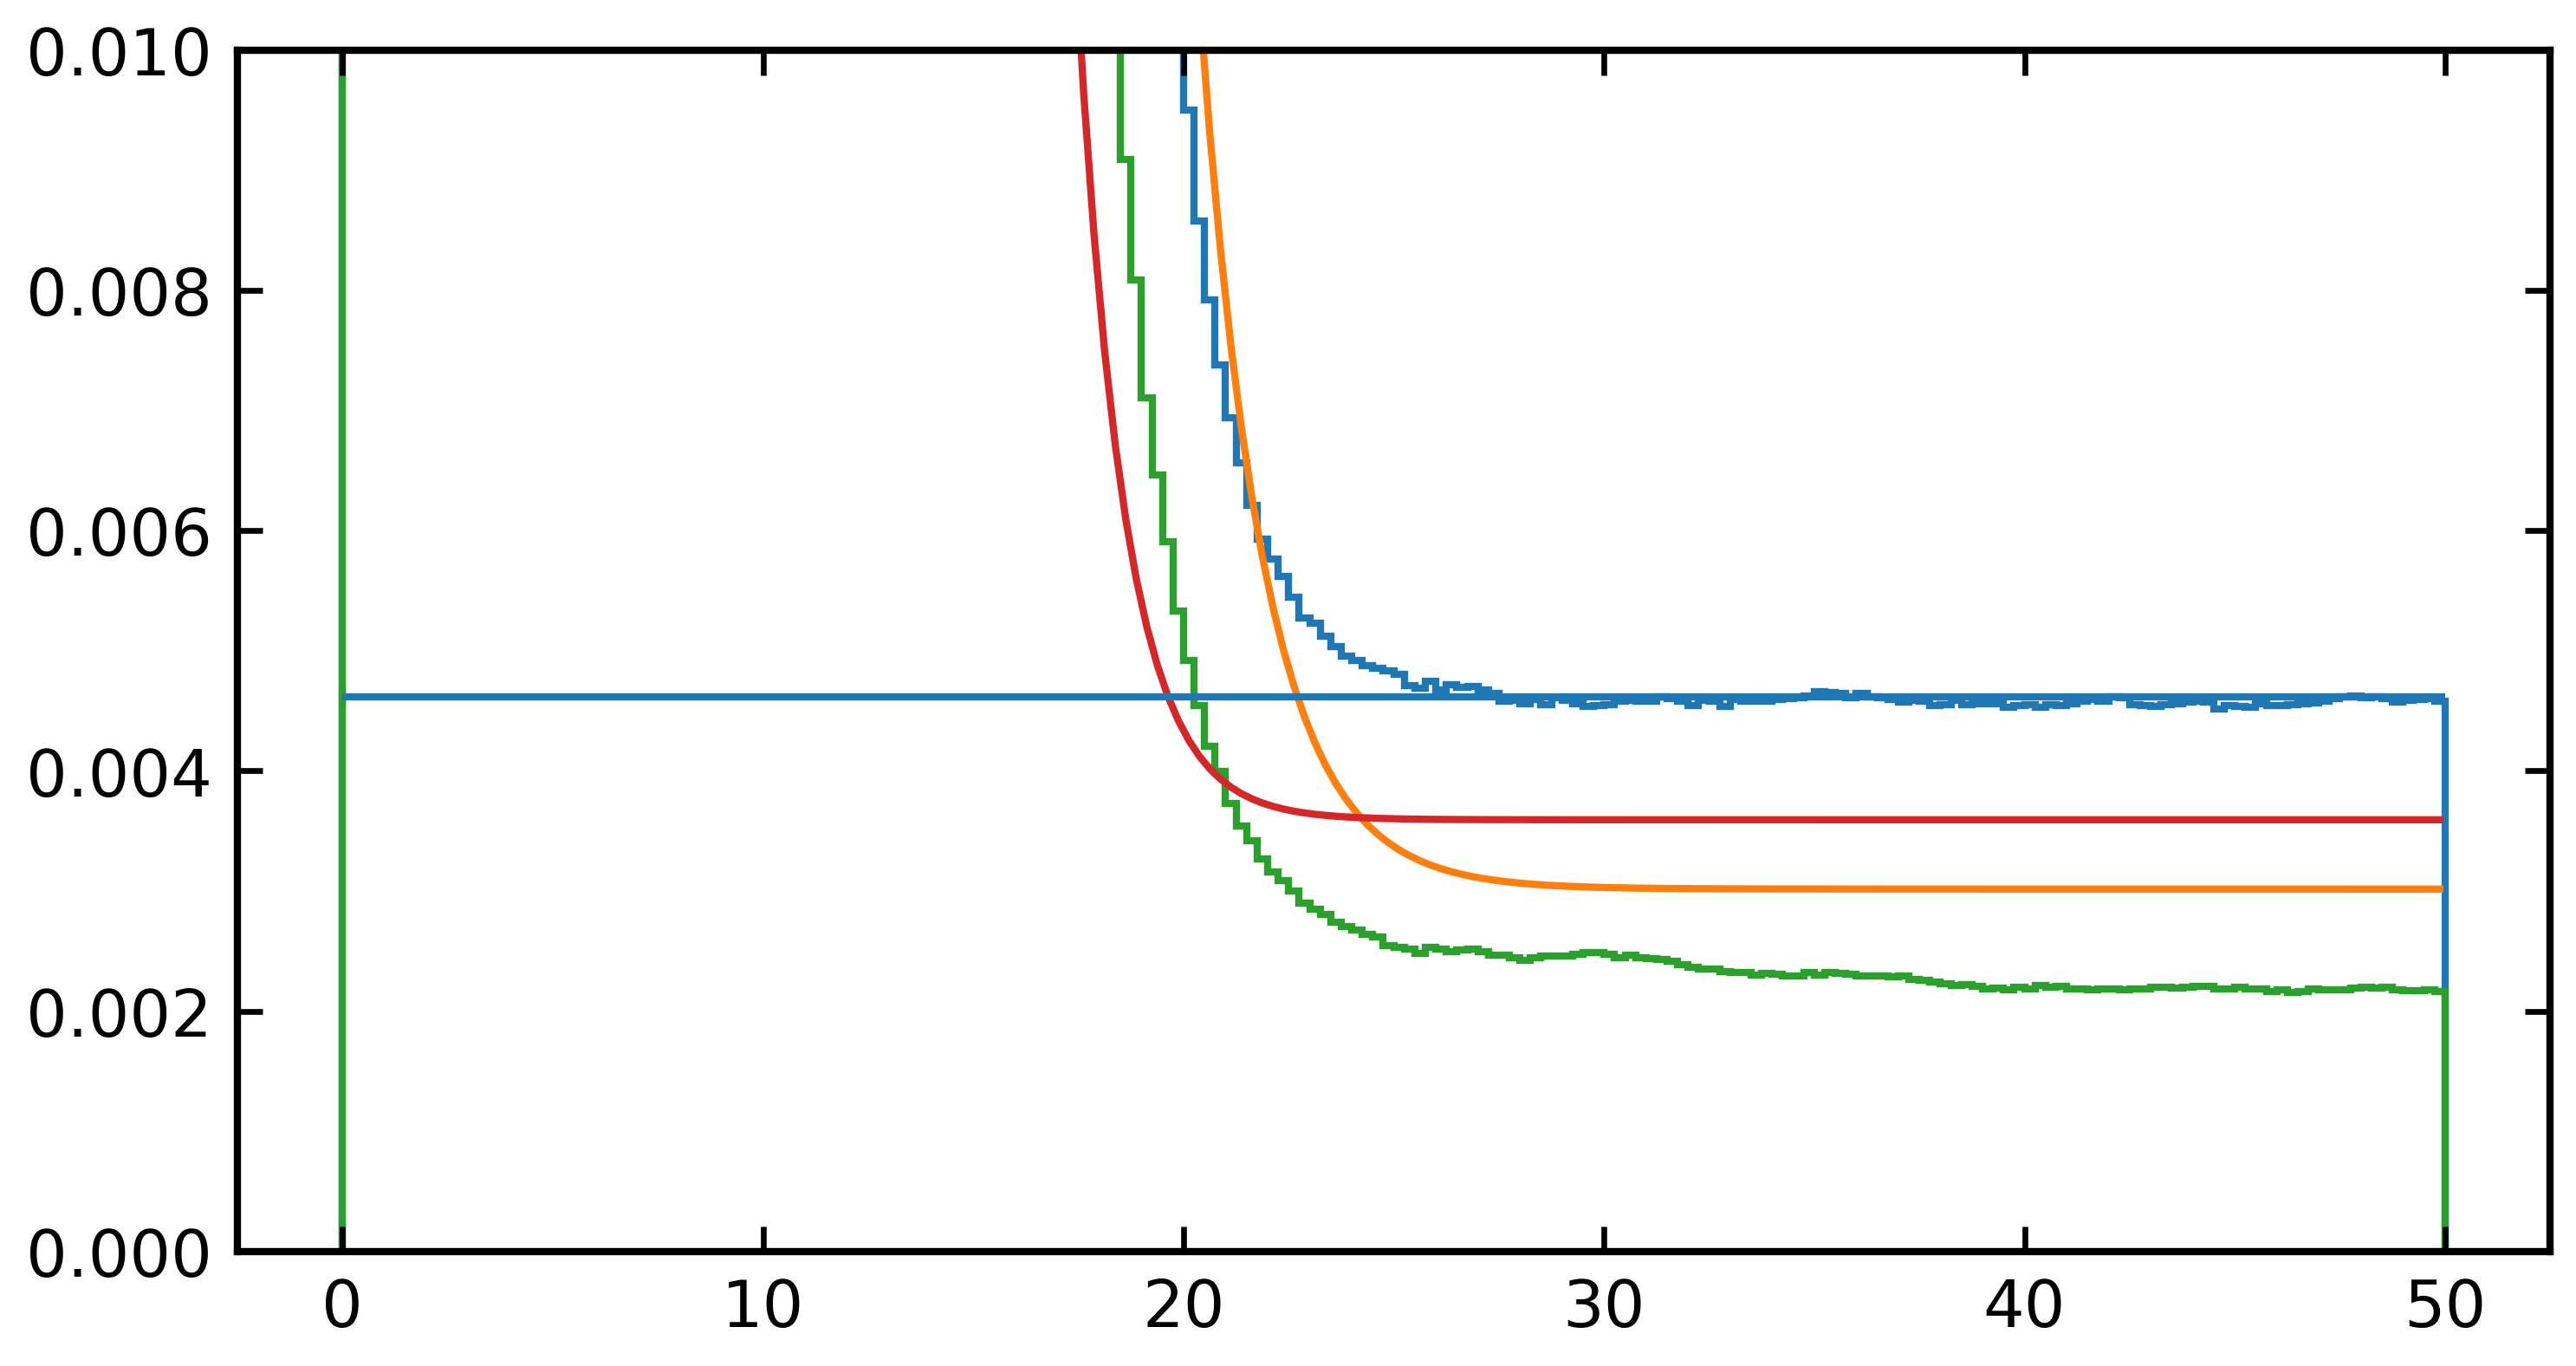

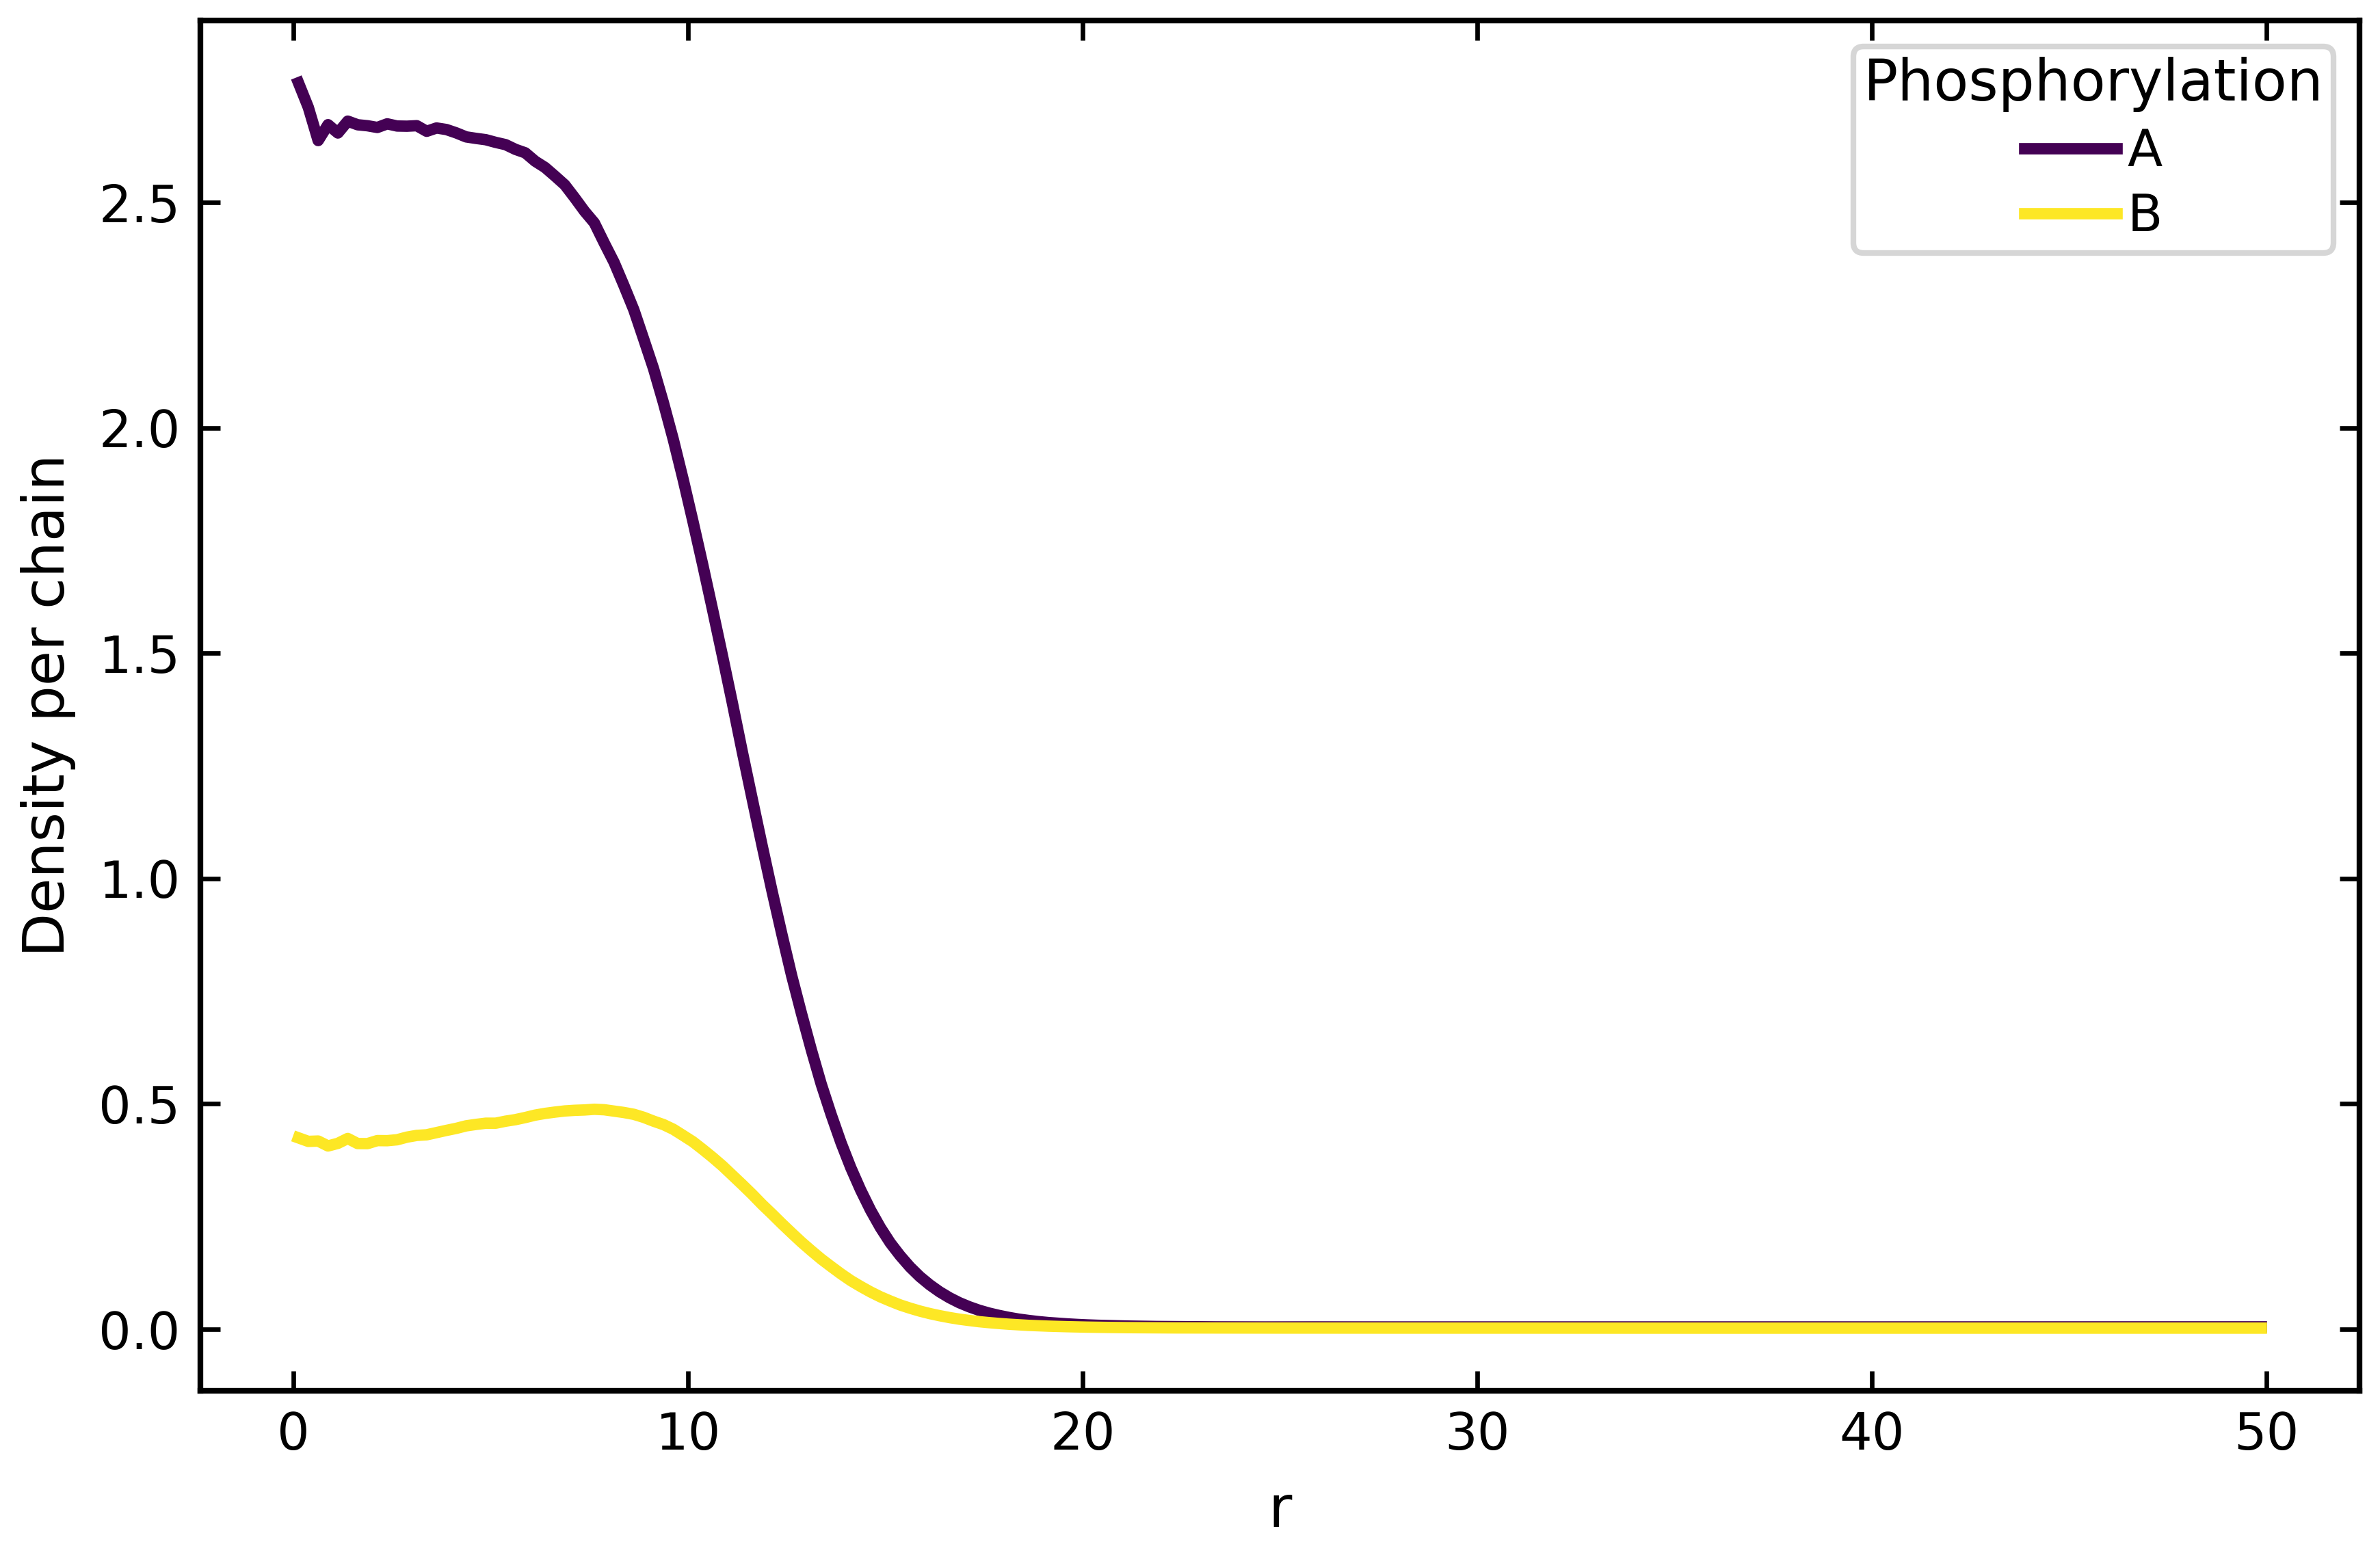

sim3 droplet condensate: 
c_in_A = 2.6838+-0.0018 res/nm^3, 
c_out_A = 0.0038+-0.0008 res/nm^3, 
w_A = 3.089+-0.010 nm, 
R_A = 11.224+-0.006 nm
sim3 droplet condensate: 
c_in_B = 0.4531+-0.0025 res/nm^3, 
c_out_B = 0.0039+-0.0012 res/nm^3, 
w_B = 2.308+-0.081 nm, 
R_B = 12.592+-0.047 nm
sim3: c_out_A(R+) = 0.00528 (r > R + 4w), 0.00512 (minimum) res/nm^3


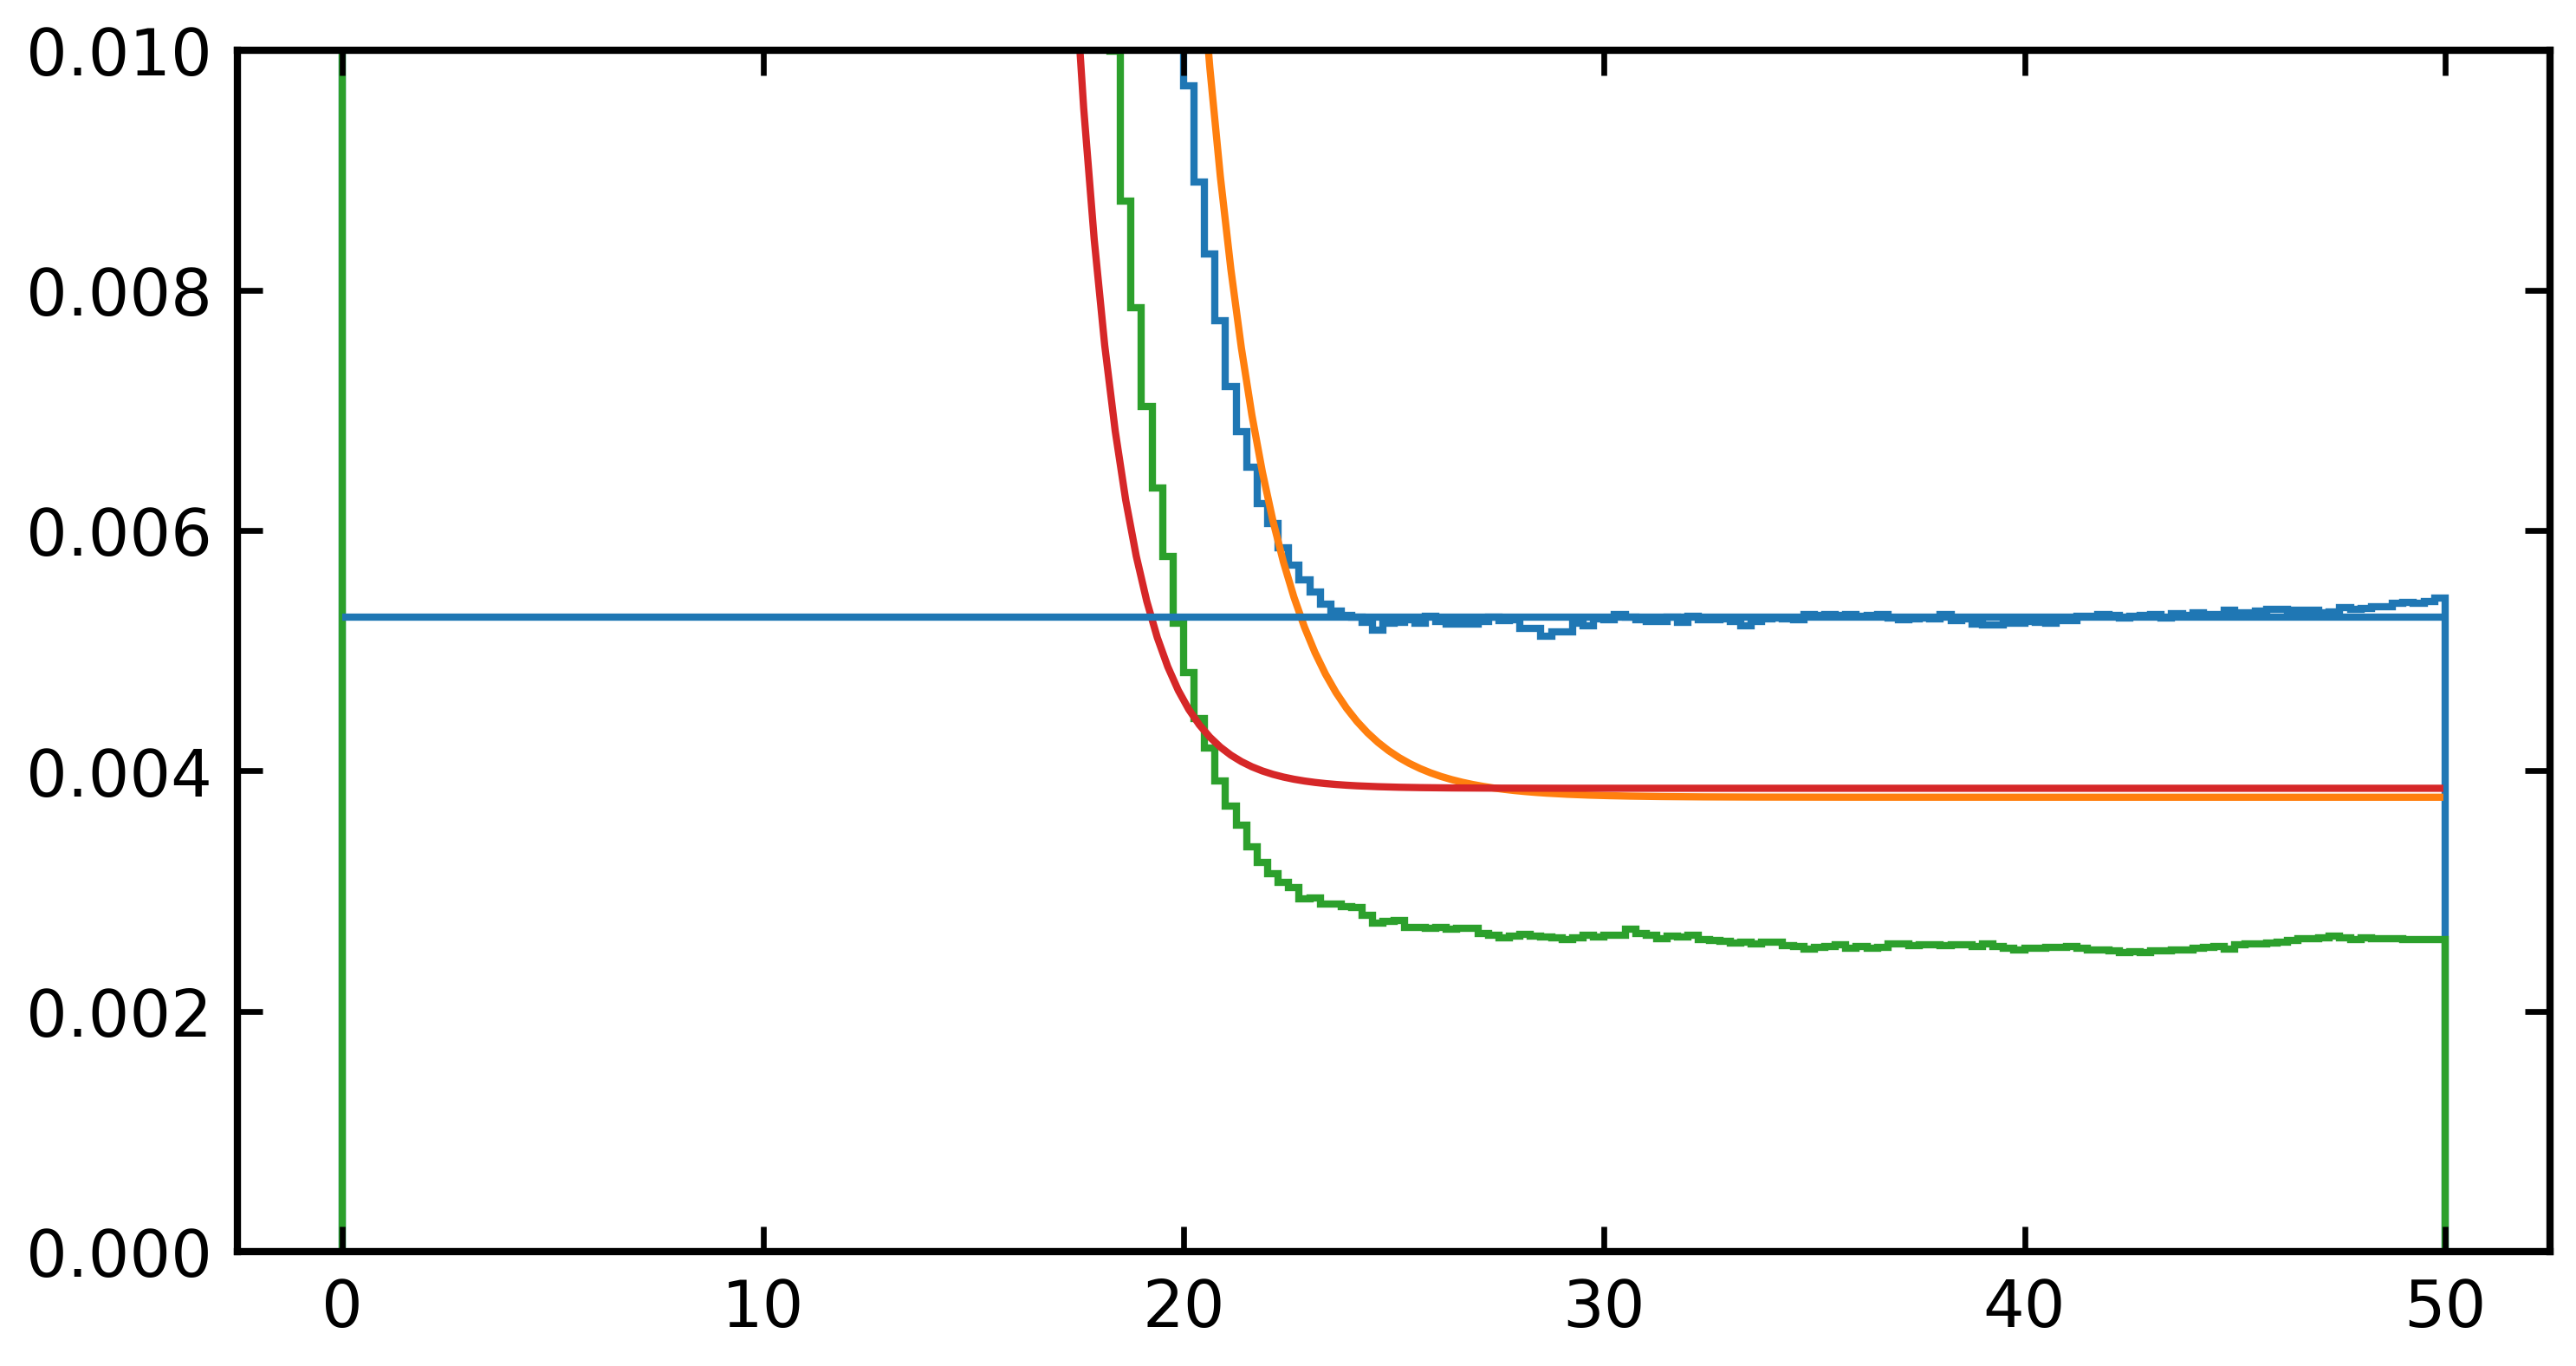

In [11]:
drop = {}   # per replica: total and A/B fits, A profile
for ss in SIMS:
    dump_c_gsd = sim_prefix(sim_type, n_k, n_p, ss) + '_fr01_20us_dump_centered.gsd'


    def compute_drop(f=dump_c_gsd):
        r_tot, d_tot = hpa.profiles.compute_radial_density_profile(f, nbins=200, group=np.arange(30800), therm=0)
        r_ab, dens, counts = hpa.profiles.compute_radial_density_by_current_npSer(f, n_chains=200, beads_per_chain=154, nbins=200)
        return dict(r_tot=r_tot, density=d_tot, r=r_ab, **profiles_to_arrays(dens, counts))

    prof = cached(an_dir(sim_type, n_k, n_p) + f'sim{ss}_radial_profiles_AB_treshold{THRESHOLD}.npz', compute_drop)
    r_dr, density_dr, r = prof['r_tot'], prof['density'], prof['r']
    densities_by_pser, chain_counts = arrays_to_profiles(prof)
    fit_tot = fit_tanh_profile(r_dr, density_dr)
    print_fit(f'sim{ss} droplet condensate', fit_tot)

    merged_profiles = hpa.plots.plot_radial_density_profiles_by_npSer(
        r, densities_by_pser, chain_counts, logscale=False, radial=True, groups=groups, per_chain=False)
    fit_AB = {k: fit_tanh_profile(r, merged_profiles[k]) for k in 'AB'}
    for k in 'AB':
        print_fit(f'sim{ss} droplet condensate', fit_AB[k], tag=f'_{k}')

    profile_A = merged_profiles['A']
    outside = r > fit_tot['R'] + 4 * fit_tot['w']
    c_out_A_dr_Rplus = profile_A[outside].mean()     # flat A profile outside the interface
    c_out_A_dr_min = np.min(profile_A)               # previous definition
    print(f'sim{ss}: c_out_A(R+) = {c_out_A_dr_Rplus:.5f} (r > R + 4w), {c_out_A_dr_min:.5f} (minimum) res/nm^3')
    drop[ss] = dict(fit_tot=fit_tot, fit_AB=fit_AB, profile_A=profile_A, r=r)

    plt.figure()
    for k in 'AB':
        plt.stairs(merged_profiles[k], stairs_edges(r))
        plt.plot(r, tanh_general(r, *fit_AB[k]['popt']))
    plt.plot([fit_AB['A']['R']], [tanh_general(fit_AB['A']['R'], *fit_AB['A']['popt'])], 'o')
    plt.hlines(c_out_A_dr_Rplus, 0, 50)
    plt.ylim(0, 0.01)

    np.savetxt(an_dir(sim_type, n_k, n_p) + f'sim{ss}_concentrations_A_for_Rstab.dat',
               [c_out_A_dr_Rplus, fit_AB['A']['c_in'], fit_tot['R'], c_out_A_sl_mean, c_out_A_dr_min],
               header='c_out_A(R+) droplet (mean for r > R+4w), c_in_A droplet, R_tot droplet, c_out_A slab, '
                      'c_out_A droplet (minimum of the A profile)   [res/nm^3, nm]')

# 3. Back-reaction rate from the A/B timelines
The 4-state timelines (A/B × in/out) are produced and saved in `droplet_msm_rates.ipynb`.
$Q$ = net A$_{in}$ → B$_{in}$ transitions per µs, $N_{A,in}$ = average number of A chains inside, $k_b = Q/N_{A,in}$.

In [12]:
Q_l, NAin_l = [], []
for ss in SIMS:
    tl = hpt.load_timelines(timelines_file(sim_type, n_k, n_p, ss))
    T_SIM_US = max(seg[-1][1] for seg in tl.values()) / 1e8      # length of the timelines in us (1e8 steps = 1 us)
    _, _, counts, residence = hpt.compute_rates(tl)
    Q_tmp = (counts[('A_in', 'B_in')] - counts[('B_in', 'A_in')]) / T_SIM_US
    NAin_tmp = residence['A_in'] / T_SIM_US / 1e8
    Q_l.append(Q_tmp)
    NAin_l.append(NAin_tmp)
    np.savetxt(an_dir(sim_type, n_k, n_p) + f'sim{ss}_Q_NAin_for_Rstab.dat', [Q_tmp, NAin_tmp],
               header='Q [1/us]   N_A_in')

Q, d_Q = mean_err(Q_l)
NAin, d_NAin = mean_err(NAin_l)
rate_back = Q / NAin
d_rate_back = rate_back * np.sqrt((d_Q / Q)**2 + (d_NAin / NAin)**2)
print(f'Q = {Q:.3} +- {d_Q:.2} 1/us,  N_A_in = {NAin:.1f} +- {d_NAin:.1f}')
print(f'k_b = {rate_back:.3}+-{d_rate_back:.2} 1/us')

Q = 4.12 +- 0.22 1/us,  N_A_in = 122.0 +- 3.4
k_b = 0.0337+-0.002 1/us


# 4. Diffusion of A chains in the dilute phase at NESS
Only chains that stay in the allowed states (from the timelines) during the whole lag window contribute.
The MSDs of every replica are saved (`sim{ss}_msd_out_treshold8.npz`) and reloaded.

In [13]:
def chain_com_trajectory(dump_files, n_chains, chain_length, t_therm=0):
    '''Unwrapped (image flags), mass-weighted COM of every chain for the frames with step >= t_therm.'''
    if isinstance(dump_files, str):
        dump_files = [dump_files]
    n_sub = n_chains * chain_length

    with gsd.hoomd.open(dump_files[0], 'r') as traj:
        m = traj[0].particles.mass[:n_sub].reshape(n_chains, chain_length)
    M = m.sum(axis=1)

    steps, com = [], []
    last_step = -1
    for f in dump_files:
        with gsd.hoomd.open(f, 'r') as traj:
            L = np.asarray(traj[0].configuration.box[:3])
            for frame in tqdm(traj, desc=f.split('/')[-1]):
                step = int(frame.configuration.step)
                if step < t_therm or step <= last_step:   # thermalization / duplicated frames
                    continue
                last_step = step
                pos = (frame.particles.position[:n_sub] + frame.particles.image[:n_sub] * L).reshape(n_chains, chain_length, 3)
                com.append(np.einsum('ij,ijk->ik', m, pos) / M[:, None])
                steps.append(step)
    return np.array(steps), np.array(com)


def msd_from_timelines(timelines, n_chains, com_data, t_therm=0, states=('A_out', 'B_out'),
                       lags=(1, 2, 3, 5, 8, 12, 20, 30, 50), origin_stride=5, step_us=1e-8):
    '''MSD of the chain COM using only chains in `states` during the whole window [t0, t0 + lag].

    com_data: (steps, com) from chain_com_trajectory. Returns lag_us, msd [nm^2], n_samples, D [nm^2/us].
    '''
    steps, com = com_data
    allowed = np.isin(hpt.states_at_frames(timelines, steps - t_therm, n_chains), states)
    msd, nsamp = masked_msd(com, allowed, lags, origin_stride)
    lag_us = np.asarray(lags) * np.median(np.diff(steps)) * step_us
    return dict(lag_us=lag_us, msd=msd, n_samples=nsamp, D=diffusion_through_origin(lag_us, msd))

sim1: D_out = 11779, D_out_A = 11884 nm^2/us
sim2: D_out = 11902, D_out_A = 12042 nm^2/us
sim3: D_out = 11674, D_out_A = 11845 nm^2/us
Diffusion coefficient of A in dilute at NESS = 11923 +- 60 nm^2/us


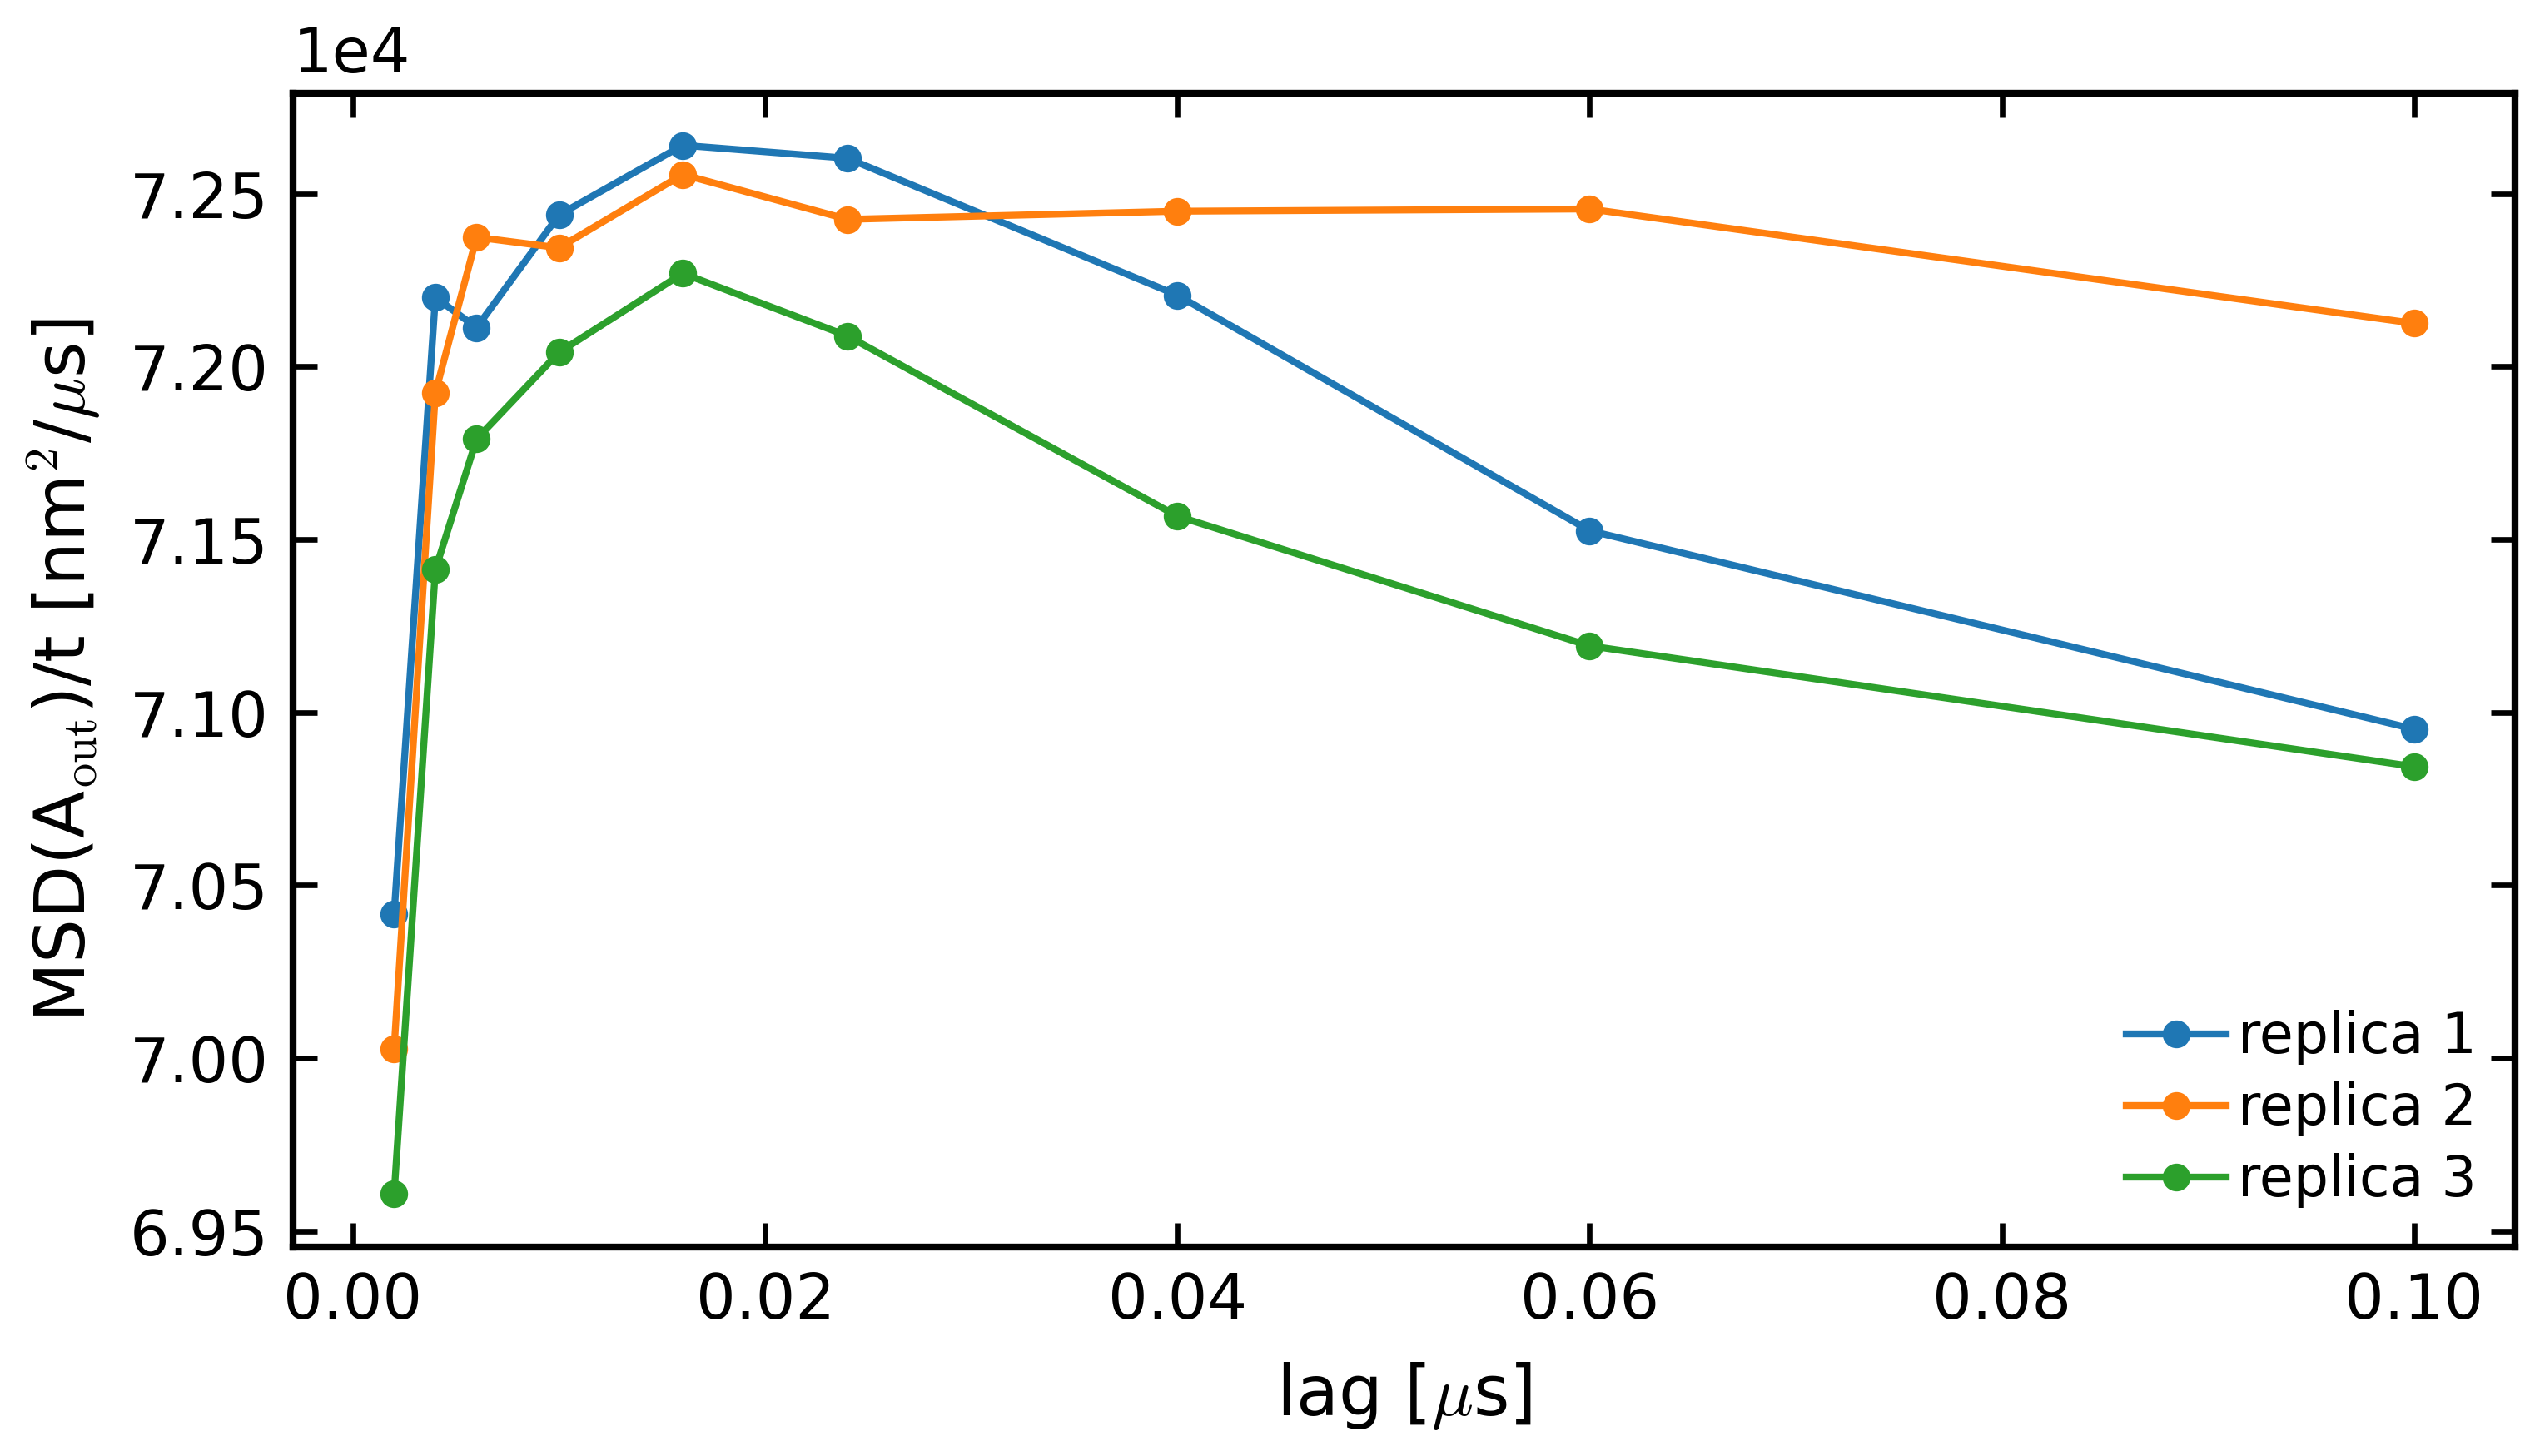

In [14]:
t_therm = 10**9   # must be the t_therm used to build the timelines

D_out_A_l = []
for ss in SIMS:

    def compute_msd(ss=ss):
        tl = hpt.load_timelines(timelines_file(sim_type, n_k, n_p, ss))
        prefix = sim_prefix(sim_type, n_k, n_p, ss)
        com_data = chain_com_trajectory([prefix + '_fr01_dump.gsd', prefix + '_fr01_20us_dump.gsd'], N_CHAINS, CHAIN_LENGTH, t_therm)
        out = msd_from_timelines(tl, N_CHAINS, com_data, t_therm=t_therm)                     # dilute: A_out + B_out
        out_A = msd_from_timelines(tl, N_CHAINS, com_data, t_therm=t_therm, states=('A_out',)) # dilute A only
        return dict(lag_us=out['lag_us'], msd=out['msd'], D=out['D'], msd_A=out_A['msd'], n_samples_A=out_A['n_samples'],
                    D_A=out_A['D'])

    m = cached(an_dir(sim_type, n_k, n_p) + f'sim{ss}_msd_out_treshold{THRESHOLD}.npz', compute_msd)
    res = dict(D=float(m['D']))
    res_A = dict(lag_us=m['lag_us'], msd=m['msd_A'], D=float(m['D_A']))
    print(f'sim{ss}: D_out = {res["D"]:.0f}, D_out_A = {res_A["D"]:.0f} nm^2/us')
    D_out_A_l.append(res_A['D'])
    np.savetxt(an_dir(sim_type, n_k, n_p) + f'sim{ss}_Dout_A_for_Rstab.dat', [res_A['D']], header='D_out_A [nm^2/us]')

    plt.plot(res_A['lag_us'], res_A['msd'] / res_A['lag_us'], 'o-', label=f'replica {ss}')   # flat if diffusive

plt.xlabel(r'lag [$\mu$s]')
plt.ylabel(r'MSD(A$_\mathrm{out}$)/t [nm$^2$/$\mu$s]')
plt.legend(frameon=False)
savefig(path_drop_fr_pl + f'{drop_name(sim_type, n_k, n_p)}/MSD_over_t_Aout_treshold{THRESHOLD}')

D_out_A, d_D_out_A = mean_err(D_out_A_l)
print(f'Diffusion coefficient of A in dilute at NESS = {int(D_out_A)} +- {int(d_D_out_A)} nm^2/us')

# 5. Stabilising radius $R_{stab}$
$R_{stab}^3 = \dfrac{3 D_{out,A} R V \Delta c_{out,A}}{2 Q}$ with $\Delta c_{out,A} = c_{out,A}(R^+) - c_{out,A}^{slab}$ (chains/nm$^3$),
computed for every replica from the files saved above; $\chi = R^3 / R_{stab}^3$.
Also given with the previous $c_{out,A}(R^+)$ (minimum of the A profile) for comparison. All the inputs and results are
written to `ostw_an/Rstab_inputs_*.txt`.

In [33]:
def r_stab_cubed(D, R, dc_res, Q):
    '''3 D R V dc / (2 Q), dc in res/nm^3 (converted to chains/nm^3).'''
    return 3 * D * R * (4 / 3 * np.pi * R**3) * (dc_res / CHAIN_LENGTH) / (2 * Q)


R_stab_3_l, R_stab_3_min_l, R_tot_dr_l, Chi_l = [], [], [], []
for ss in SIMS:
    an = an_dir(sim_type, n_k, n_p)
    D_out_A_ss = np.loadtxt(an + f'sim{ss}_Dout_A_for_Rstab.dat')
    Q_ss, NAin_ss = np.loadtxt(an + f'sim{ss}_Q_NAin_for_Rstab.dat')
    c_out_A_dr_Rplus, c_in_A_dr, R_tot_dr, c_out_A_sl, c_out_A_dr_min = np.loadtxt(an + f'sim{ss}_concentrations_A_for_Rstab.dat')

    R_stab_3_l.append(r_stab_cubed(D_out_A_ss, R_tot_dr, c_out_A_dr_Rplus - c_out_A_sl, Q_ss))
    R_stab_3_min_l.append(r_stab_cubed(D_out_A_ss, R_tot_dr, c_out_A_dr_min - c_out_A_sl, Q_ss))
    Chi_l.append(R_tot_dr**3 / R_stab_3_l[-1])
    R_tot_dr_l.append(R_tot_dr)


def cube_root_mean_err(values):
    '''(mean of the cubes)^(1/3) and its standard error.'''
    r = np.mean(values)**(1 / 3)
    return r, (1 / 3) * np.std(values) / np.sqrt(len(values) - 1) / r**2


R_stab, d_R_stab = cube_root_mean_err(R_stab_3_l)
R_stab_min, d_R_stab_min = cube_root_mean_err(R_stab_3_min_l)
R_drop, d_R_drop = mean_err(R_tot_dr_l)
chi, d_chi = mean_err(Chi_l)
print(f'R_stab = {R_stab:.2f} +- {d_R_stab:.2f} nm (c_out_A(R+) for r > R + 4w; {R_stab_min:.2f} +- {d_R_stab_min:.2f} nm with '
      f'the minimum) | R_drop = {R_drop:.2f} +- {d_R_drop:.2f} nm | chi = {chi:.3f} +- {d_chi:.3f}')

summary = [('D_dilute_single_chain [nm^2/us]', D_out, dD_out),
           ('D_dense_eq_droplet [nm^2/us]', D_in, np.nan), ('D_out_A_NESS [nm^2/us]', D_out_A, d_D_out_A),
           ('Q [1/us]', Q, d_Q), ('N_A_in', NAin, d_NAin), ('k_b [1/us]', rate_back, d_rate_back),
           ('R_drop [nm]', R_drop, d_R_drop), ('R_stab [nm]', R_stab, d_R_stab),
           ('R_stab_minimum_definition [nm]', R_stab_min, d_R_stab_min), ('chi', chi, d_chi)]
with open(ostw_an + f'Rstab_inputs_{drop_name(sim_type, n_k, n_p)[4:]}_treshold{THRESHOLD}.txt', 'w') as fh:
    fh.write('# quantity value error\n')
    for name, v, e in summary:
        fh.write(f'{name} {v:.6g} {e:.3g}\n')

R_stab = 15.71 +- 0.21 nm (c_out_A(R+) for r > R + 4w; 15.30 +- 0.23 nm with the minimum) | R_drop = 11.56 +- 0.05 nm | chi = 0.401 +- 0.020


# Ostwald ripening
Two droplets (400 LCD chains, 4 CK1δ, 48 PP3): number of chains in the two largest clusters in time, active vs passive (no reactions).
The `sim11_*` runs continue replica 11 of the passive runs, with (active) and without (passive) reactions.
Cluster sizes saved in `ostw_an` (`two_largest_clusters_{run}.npz`) and reloaded.

In [16]:
path_ostw = SIM + 'ostwald_ripening/'
path_ostw_pl = PL + 'ostwald_ripening/'
OSTW_FILE = '400-tdp43-lcd_4-com-ck1d-open_48-com-pp3_CAL3_fr01_dump.gsd'
frames_ostw = np.arange(5, 2505, 5) - 1     # every 5th dump frame


def two_largest_clusters(name, folder, prefix, sims, frames):
    '''Chains in the two largest clusters, shape (n_frames, 2), for every replica (saved in ostw_an/two_largest_clusters_{name}.npz).'''
    def compute():
        return {f'sim{s}': hpa.cluster.chains_in_condensate(path_ostw + folder, prefix + OSTW_FILE, [s], frames,
                                                            n_particles=61600, n_clusters=2)[0] for s in sims}
    d = cached(ostw_an + f'two_largest_clusters_{name}.npz', compute)
    return {s: d[f'sim{s}'] for s in sims}


ostw = {
    'active': two_largest_clusters('active', 'sim_400-tdp43-lcd_4-ck1d-open_48-pp3_fr01/', '', [1, 2, 11, 21], frames_ostw),
    'passive': two_largest_clusters('passive', 'sim_eq_400-tdp43-lcd_4-ck1d-open_48-pp3_fr01/', 'eq_', [1, 2, 11, 21], frames_ostw),
    'active_cont': two_largest_clusters('active_cont', 'sim11_400-tdp43-lcd_4-ck1d-open_48-pp3_fr01/', '', [1, 2, 3],
                                        frames_ostw[:-30]),
    'passive_cont': two_largest_clusters('passive_cont', 'sim11_eq_400-tdp43-lcd_4-ck1d-open_48-pp3_fr01/', 'eq_', [1, 2, 3],
                                         frames_ostw[:-30]),
}
time_ostw = frames_ostw * DT_SNAP / 1e8

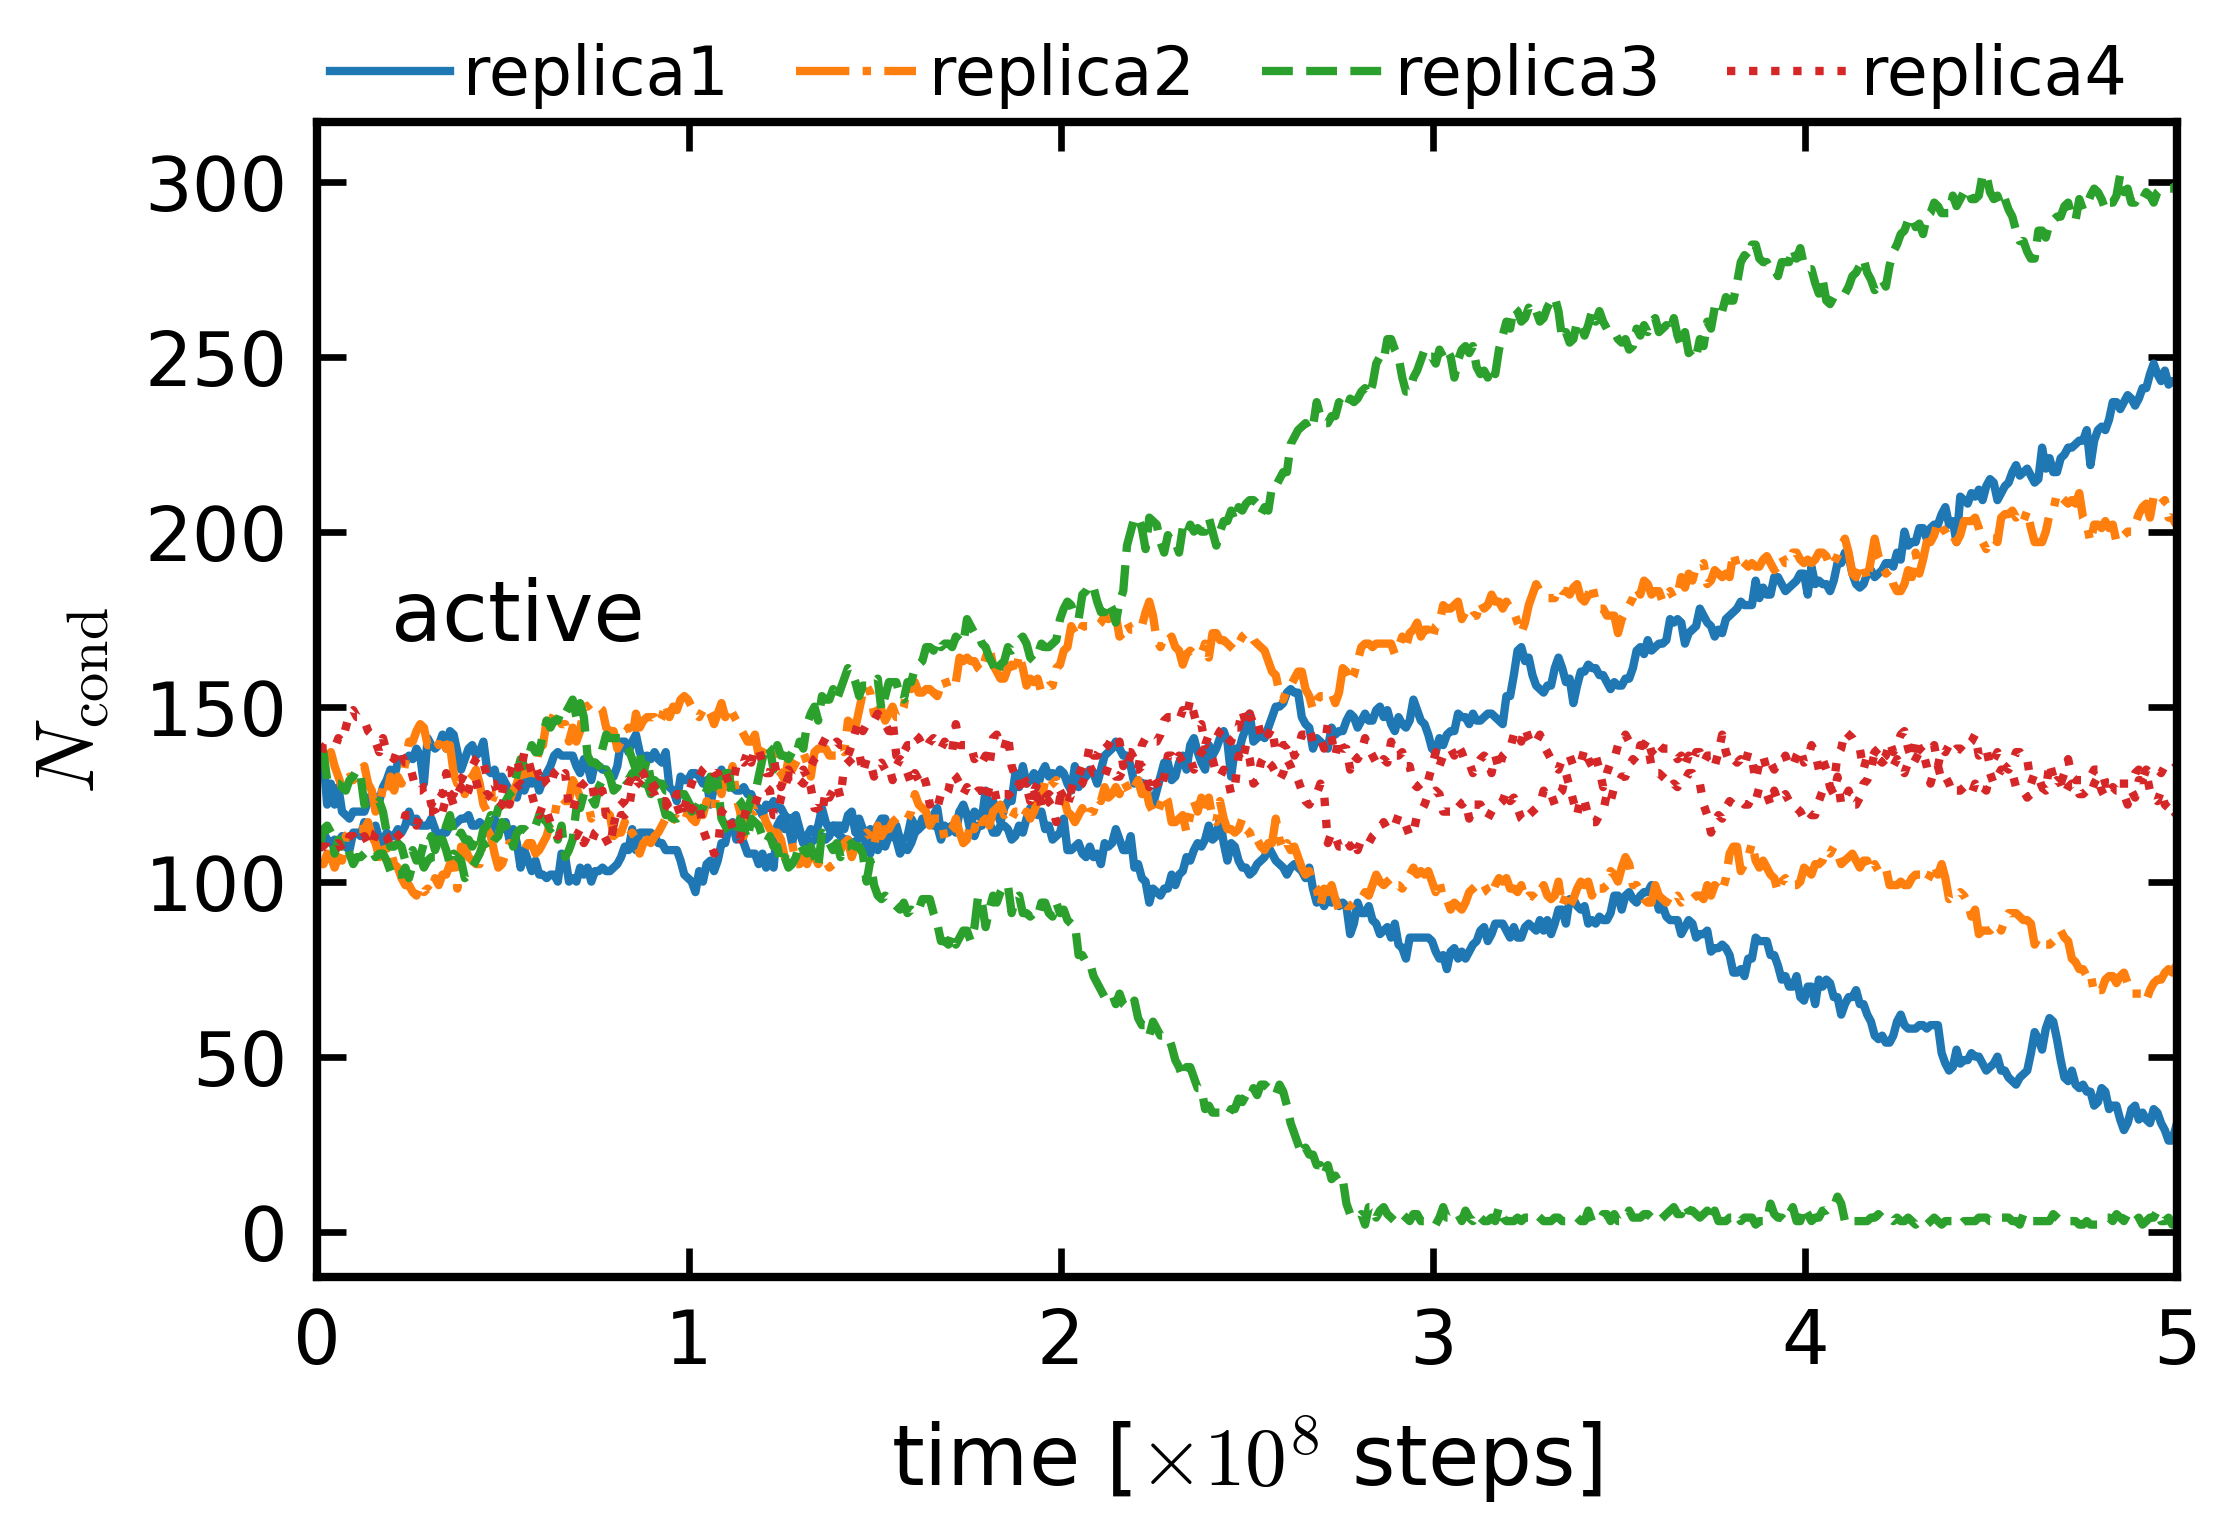

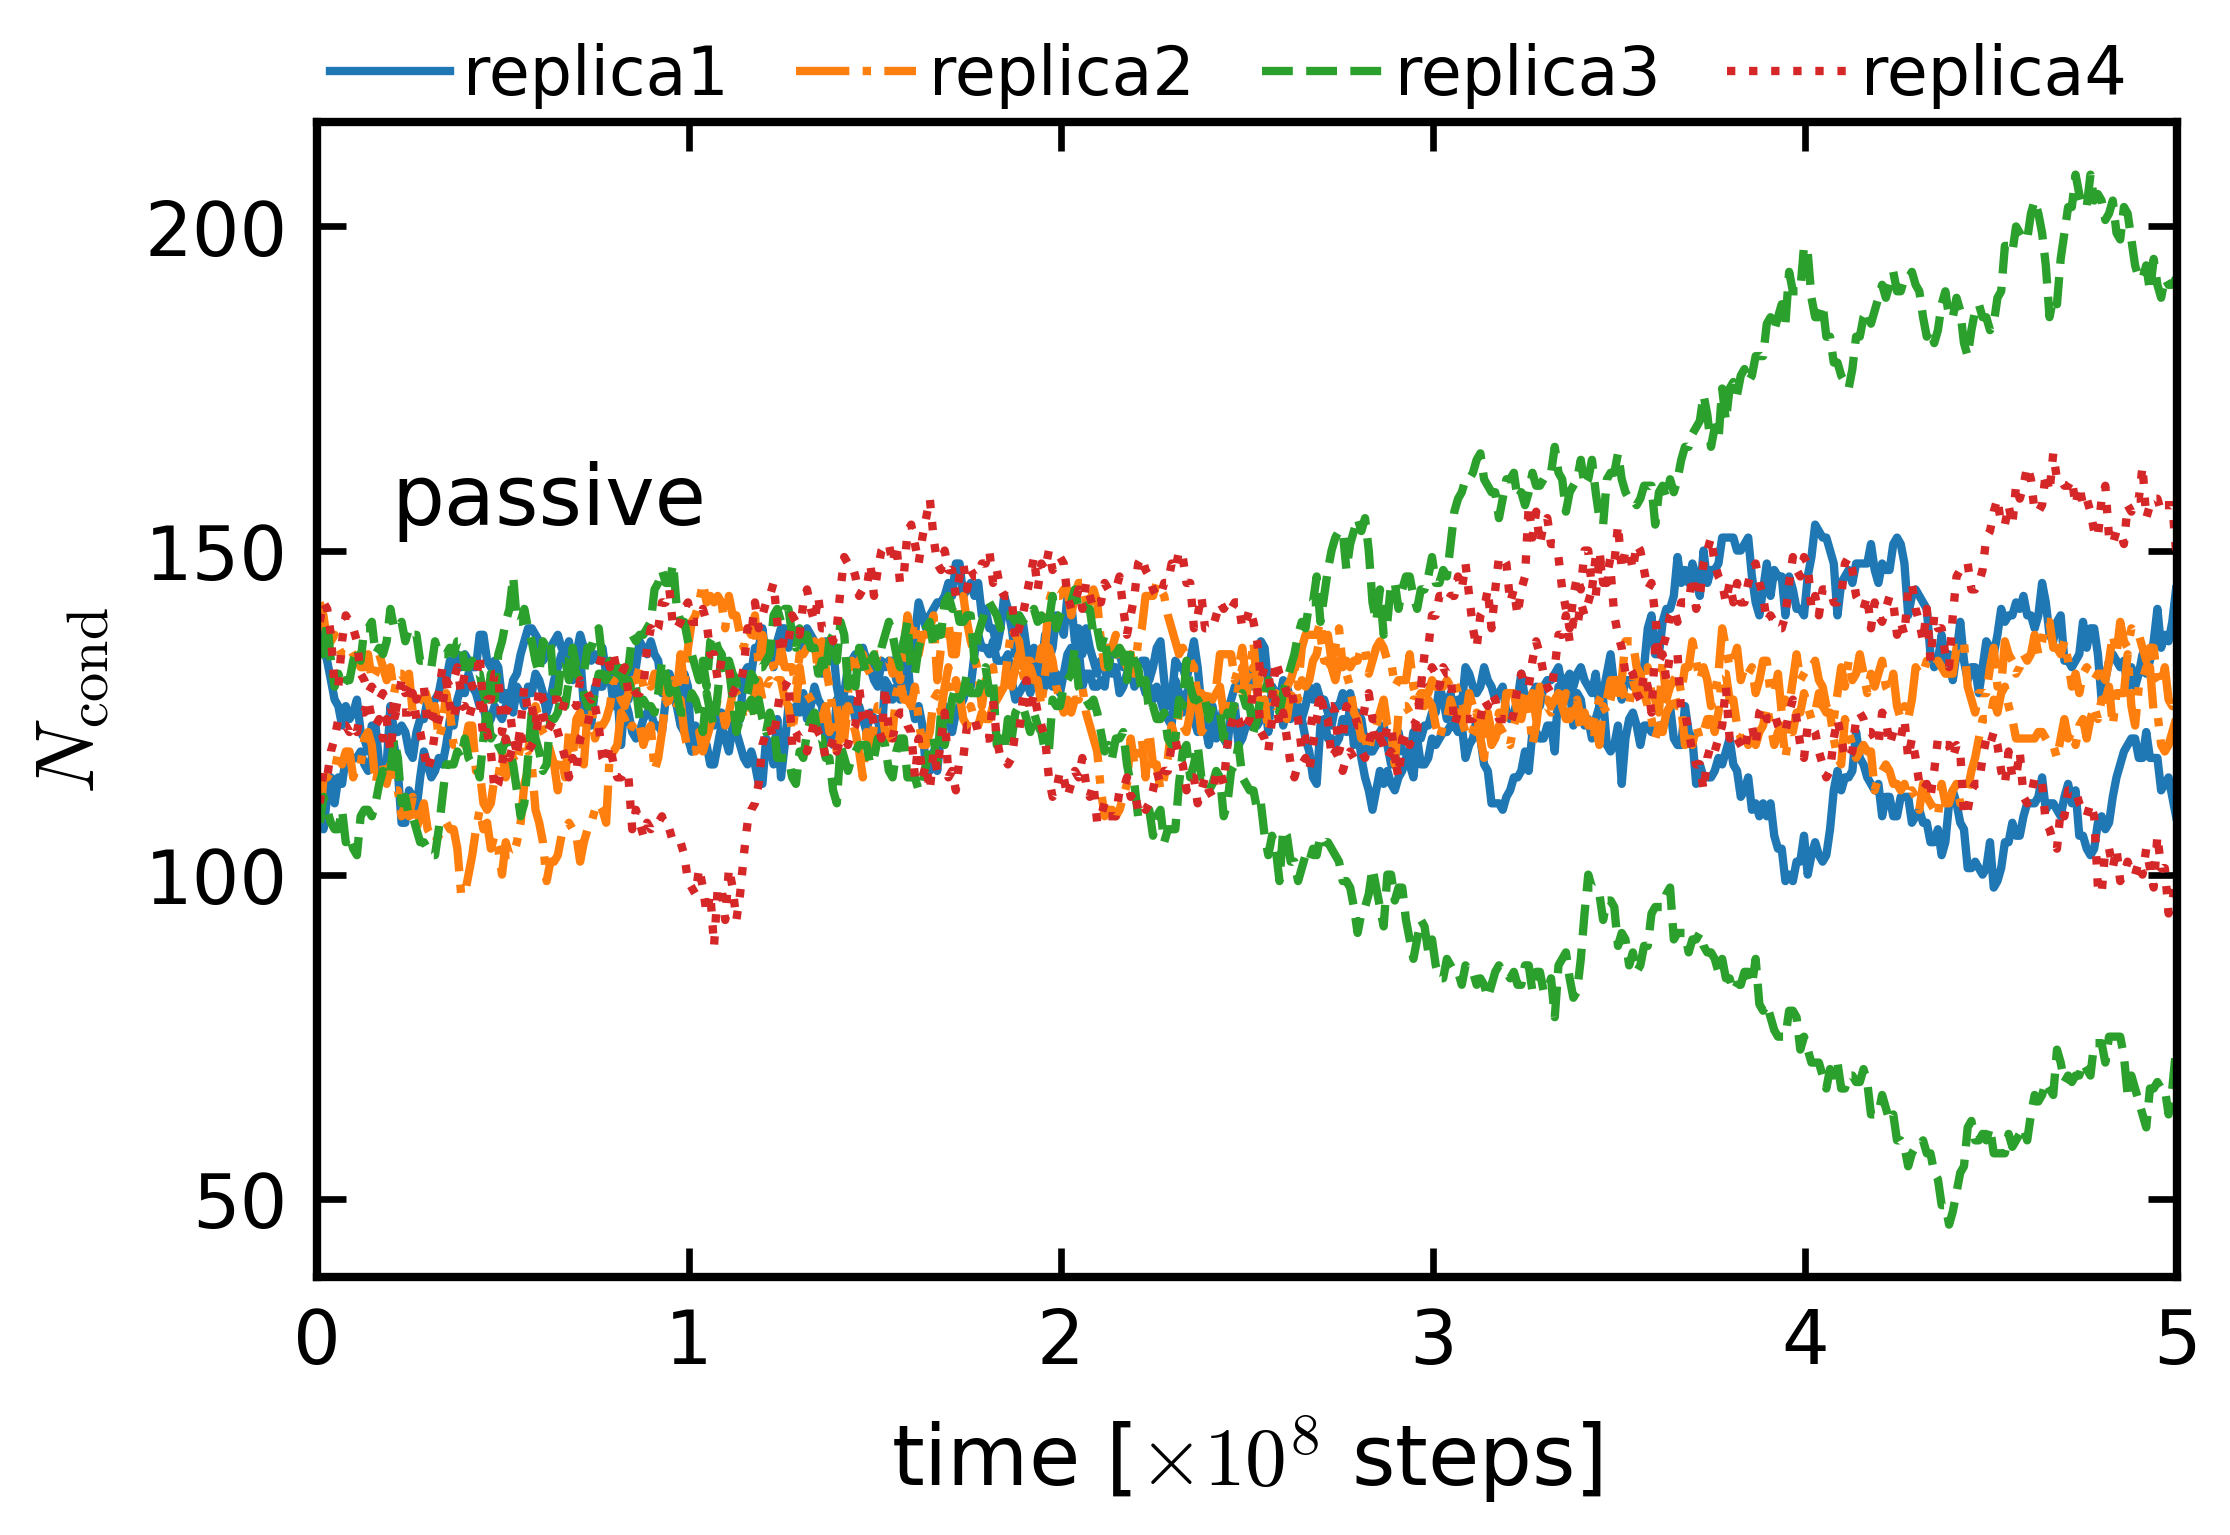

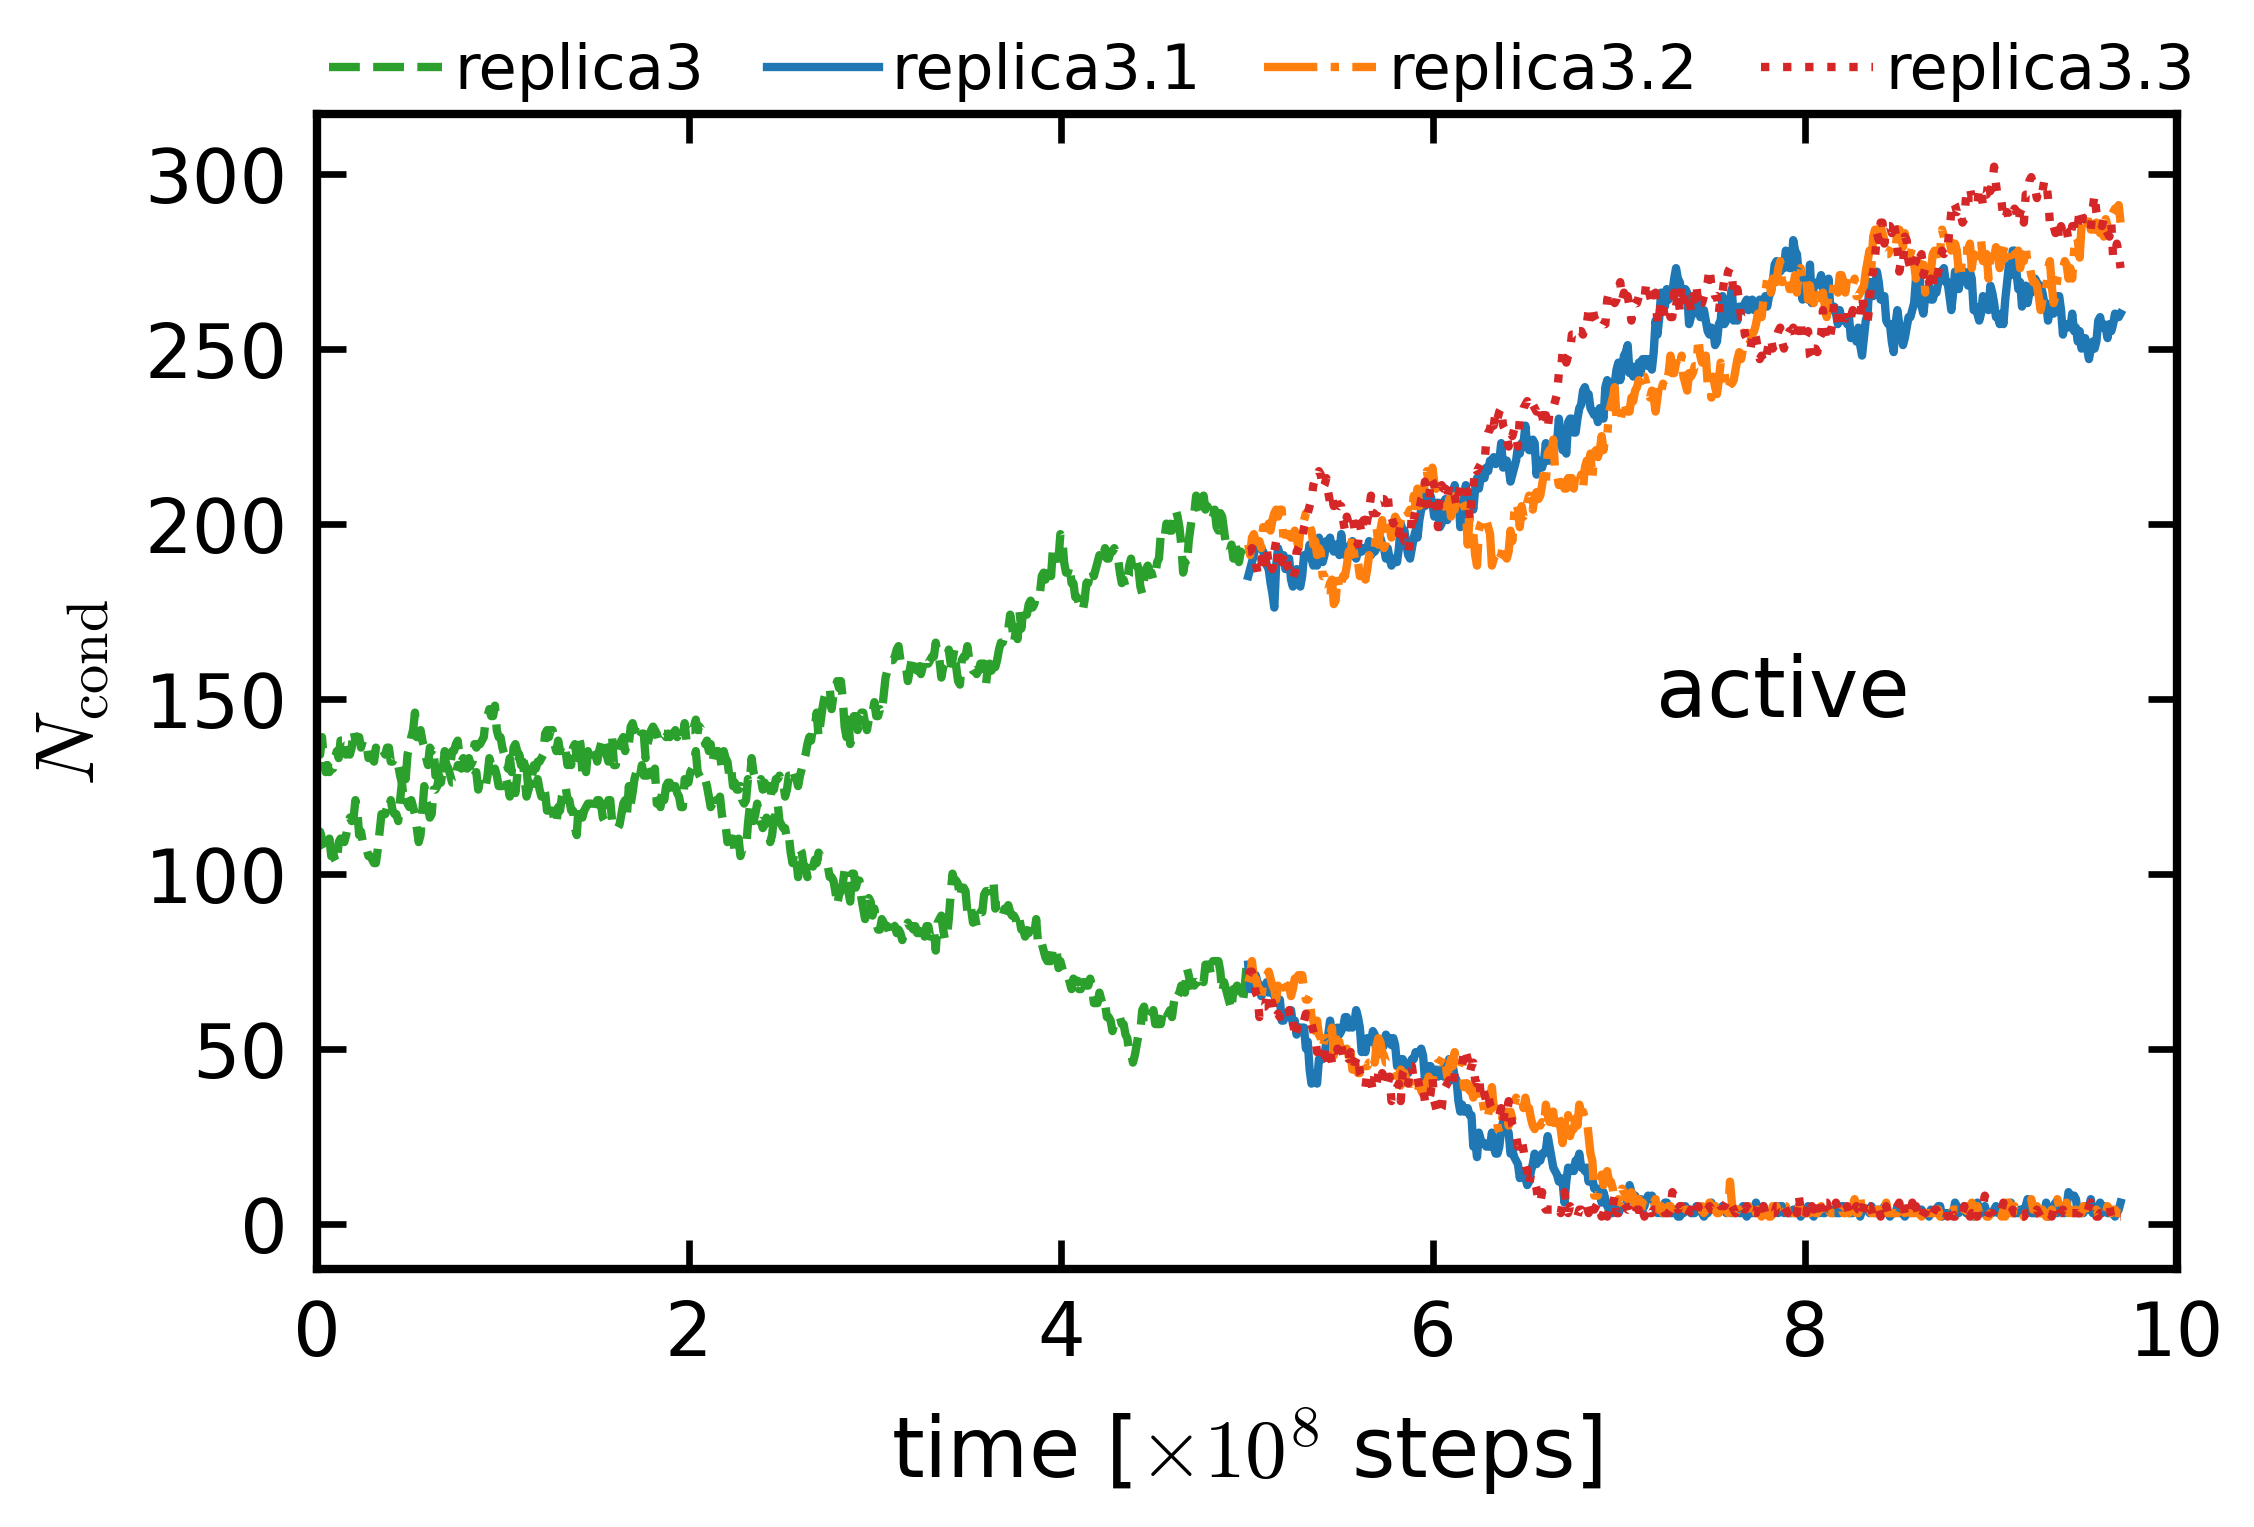

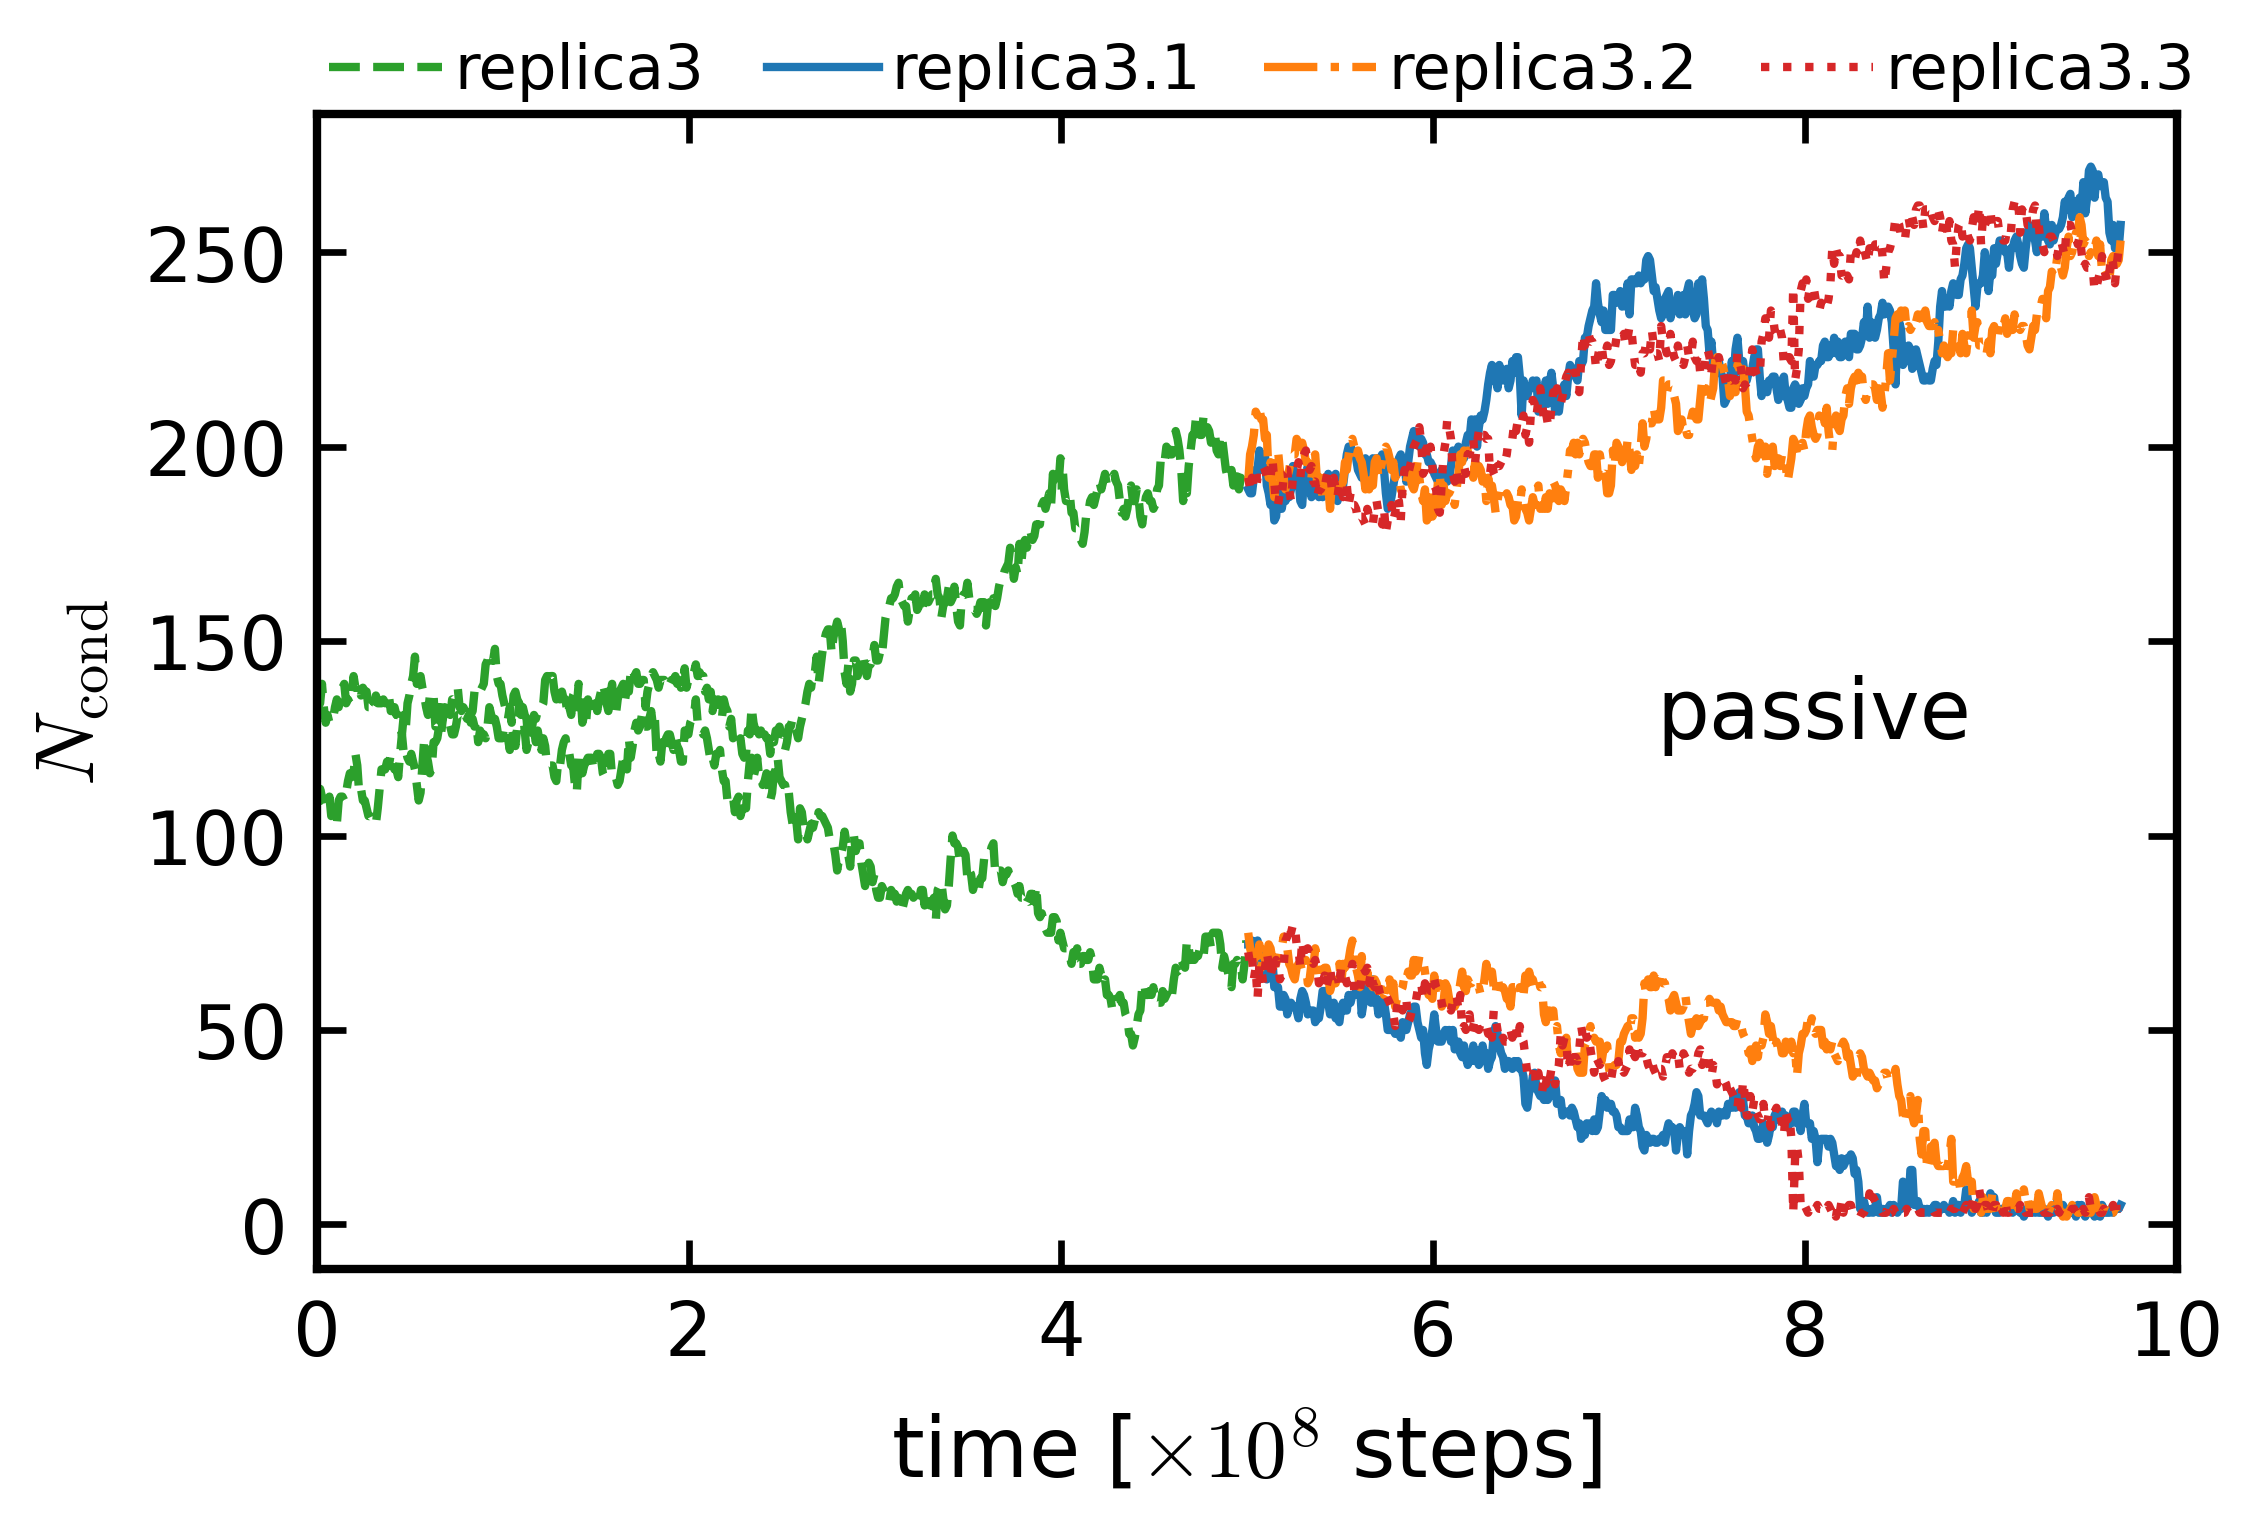

In [17]:
STYLES = [('-', 'tab:blue'), ('-.', 'tab:orange'), ('--', 'tab:green'), (':', 'tab:red')]


def plot_two_clusters(ax, t, runs, labels, styles=STYLES):
    '''Both cluster sizes of every run with the same line style.'''
    for (ls, color), nc, label in zip(styles, runs, labels):
        ax.plot(t, nc[:, 0], ls, c=color, label=label)
        ax.plot(t, nc[:, 1], ls, c=color)


def finish_two_clusters(ax, xlim, text, filename, fontsize=None):
    ax.set_xlim(0, xlim)
    ax.set_xlabel(r'time [$\times 10^8$ steps]')
    ax.set_ylabel(r'$N_\mathrm{cond}$')
    ax.text(*text)
    ax.legend(loc=(-0.0, 1.), ncols=4, frameon=False, fontsize=fontsize)
    savefig(path_ostw_pl + filename, dpi=600)


# from the two-droplet start
for mode, text, suffix in [('active', (0.2, 169, 'active'), ''), ('passive', (0.2, 154, 'passive'), '_equilibrium')]:
    fig, ax1 = plt.subplots(figsize=(4, 2.5))
    plot_two_clusters(ax1, time_ostw, ostw[mode].values(), [f'replica{k}' for k in range(1, 5)])
    finish_two_clusters(ax1, 5, text, f'2clusters_size_4-ck1d_48-pp3{suffix}')

# continuation of passive replica 11 (replica3) with and without reactions
for mode, text, suffix in [('active_cont', (7.2, 145, 'active'), ''), ('passive_cont', (7.2, 125, 'passive'), '_equilibrium')]:
    fig, ax1 = plt.subplots(figsize=(4, 2.5))
    plot_two_clusters(ax1, time_ostw, [ostw['passive'][11]], ['replica3'], styles=[('--', 'tab:green')])
    plot_two_clusters(ax1, time_ostw[:-30] + 5, ostw[mode].values(), ['replica3.1', 'replica3.2', 'replica3.3'],
                      styles=[STYLES[0], STYLES[1], STYLES[3]])
    finish_two_clusters(ax1, 10, text, f'sim11-b_2clusters_size_4-ck1d_48-pp3{suffix}', fontsize=7.5)